# 01. EDA và Tiền xử lý – LYCOS-IDS2017

Notebook đi theo đúng 12 mục trong `00_documents/EDA - PREPROCESS.md`, dựa trên bộ dữ liệu đã gộp
`02_merge_data/data_raw.csv` (1.837.498 luồng mạng, 84 cột gốc). Ý nghĩa và miền hợp lệ của từng cột
lấy từ `00_documents/Explain_LYCOS_IDS2017.md`.

Biến mục tiêu chính là `is_attack` (luồng có bị tấn công hay không). Nhãn gốc `label` gồm 14 lớp,
được giữ lại để mô tả và cho phần kho dữ liệu.

Kết quả của notebook này là `artifacts/flows_clean.parquet` – đầu vào của `02_data_warehouse.ipynb`
và `03_association_classifiation.ipynb`. Nên thêm `artifacts/` vào `.gitignore` vì tệp này lớn.

# Import

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
from scipy.stats import f_oneway

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

pd.set_option('display.max_columns', None)

In [2]:
# Tham số chung
RANDOM_STATE = 42

# Dữ liệu có 1,8 triệu dòng nên các bước nặng chạy trên mẫu; phân bố không đổi đáng kể
SAMPLE_PLOT = 200_000     # vẽ biểu đồ và kiểm định
SAMPLE_MI = 300_000       # tính Mutual Information
SAMPLE_MODEL = 200_000    # thử nghiệm mô hình khi chọn thuộc tính

OUT_DIR = Path('artifacts')
OUT_DIR.mkdir(exist_ok=True)

# 01. Load Data & Data Dictionary

In [3]:
# Trước đó có chạy câu lệnh -> để unzip và lấy nhãn

# cd lycos-ids2017
# for zip_file in pcap_lycos/*.zip; do unzip -n "$zip_file" -d pcap_lycos; done
# python3 labelling.py

In [4]:
# Gộp 5 tệp theo ngày thành một bộ dữ liệu; chỉ chạy một lần

# folder_order = "01_raw_data"

# file_list = sorted(
#     os.path.join(folder_order, file)
#     for file in os.listdir(folder_order)
#     if file.endswith('.csv')
# )

# df_list = []
# for file in file_list:
#     df_day = pd.read_csv(file)
#     df_day['source_day'] = os.path.basename(file).split('-')[0]
#     df_list.append(df_day)

# df_raw = pd.concat(df_list, ignore_index=True)
# del df_list, df_day

# df_raw.to_csv("02_merge_data/data_raw.csv", index=False)

In [5]:
# Đọc từ file đã merge
df_raw = pd.read_csv("02_merge_data/data_raw.csv")

columns_raw = df_raw.columns.tolist()
print("Số dòng:", len(df_raw))
print("Số cột gốc:", len(columns_raw))

df_raw.head()

Số dòng: 1837498
Số cột gốc: 84


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.0,403.0,0.0,158.333333,31450.099291,177.341758,67.411331,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.0,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.5,403.0,0.0,239.666667,30619.460993,174.984174,102.039585,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.0,8.0,8.0,8.000000,0.000000,0.000000,584.368152,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.0,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,584.368152,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.0,28.0,28.0,28.000000,0.000000,0.000000,6152.248167,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.0,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6152.248167,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.0,68.0,50.0,59.000000,46.153846,6.793662,25.357414,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.0,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.341593e+06,50763066.0,28899219.0,3.983114e+07,1.546007e+07,0,

In [6]:
# Chỉ dự báo xem có bị tấn công hay không
df_raw["is_attack"] = np.where(
    df_raw["label"].str.lower().eq("benign"),
    "safe",
    "attack"
)
df_raw["is_attack"] = df_raw["is_attack"].eq("attack").astype("int8")

print(df_raw["is_attack"].value_counts())

is_attack
0    1395675
1     441823
Name: count, dtype: int64


In [7]:
# Bản tiếng Việt chỉ dùng để trình bày trong báo cáo, không dùng để tính toán

# rename_map = {
#     'flow_id': 'Mã luồng',
#     'src_addr': 'IP nguồn',
#     'src_port': 'Cổng nguồn',
#     'dst_addr': 'IP đích',
#     'dst_port': 'Cổng đích',
#     'ip_prot': 'Giao thức IP',
#     'timestamp': 'Thời điểm bắt đầu',
#     'label': 'Nhãn phân lớp',
#     'source_day': 'Ngày nguồn dữ liệu',
#     'is_attack': 'Có tấn công',
# }

# df_vn = df_raw.rename(columns=rename_map)
# df_vn.to_csv('02_merge_data/data_vn.csv', index=False)

In [8]:
# Phân vai trò các cột
target_col = "is_attack"
label_col = "label"

# Cột định danh: duy nhất hoặc gắn với hạ tầng cụ thể nên không đưa vào mô hình
id_cols = ["flow_id", "src_addr", "dst_addr", "timestamp"]

# ip_prot, src_port, dst_port là mã phân loại chứ không phải đại lượng liên tục
code_cols = ["ip_prot", "src_port", "dst_port"]

# -1 ở hai cột cửa sổ TCP là mã "không ghi nhận", không phải kích thước âm
sentinel_cols = ["fwd_tcp_init_win_bytes", "bwd_tcp_init_win_bytes"]

# Chỉ ip_prot đủ ít giá trị để coi là biến rời rạc khi tính Mutual Information.
# src_port và dst_port có hàng chục nghìn giá trị; đánh dấu rời rạc sẽ thổi MI lên
# vì mỗi cổng gần như chỉ xuất hiện trong một nhóm nhỏ bản ghi.
discrete_cols = ["ip_prot"]

# Cổng nguồn do hệ điều hành cấp phát theo từng kết nối nên gần như định danh phiên.
# Giữ lại cho chiều kho dữ liệu nhưng không tin vào điểm MI của nó.
quasi_id_cols = ["src_port"]

numeric_cols = df_raw.select_dtypes(include='number').columns.drop(target_col).tolist()
category_cols = df_raw.select_dtypes(exclude='number').columns.tolist()

print("Số cột numeric:", len(numeric_cols))
print("Các cột không phải số:", category_cols)

Số cột numeric: 79
Các cột không phải số: ['flow_id', 'src_addr', 'dst_addr', 'label', 'source_day']


In [9]:
# Đại lượng đo không thể âm; loại mã phân loại, thời điểm và hai cột có mã -1
nonnegative_cols = [
    col for col in numeric_cols
    if col not in code_cols + ["timestamp"] + sentinel_cols
]

print("Số cột phải không âm:", len(nonnegative_cols))

Số cột phải không âm: 73


In [10]:
# Nhóm thuộc tính theo ý nghĩa, dùng cho từ điển dữ liệu
group_map = {
    "Định danh & kết nối": ["flow_id", "src_addr", "src_port", "dst_addr", "dst_port", "ip_prot", "timestamp"],
    "Nhãn & nguồn dữ liệu": ["label", "source_day", "is_attack"],
    "Cửa sổ TCP ban đầu": sentinel_cols,
}


def infer_group(col):
    for group, cols in group_map.items():
        if col in cols:
            return group
    if "subflow" in col:
        return "Luồng con (subflow)"
    if "bulk" in col:
        return "Nhóm truyền liên tiếp (bulk)"
    if "flag" in col:
        return "Cờ TCP"
    if col.startswith(("active", "idle")):
        return "Giai đoạn hoạt động & nghỉ"
    if "iat" in col:
        return "Khoảng thời gian liên gói (IAT)"
    if "hdr_len" in col:
        return "Độ dài header"
    if "pkt_len" in col:
        return "Kích thước gói"
    if "pkt_cnt" in col or "per_s" in col:
        return "Số gói & tốc độ"
    return "Thời lượng & tỷ lệ luồng"


def infer_role(col):
    if col == target_col:
        return "Biến mục tiêu (nhị phân)"
    if col == label_col:
        return "Nhãn gốc 14 lớp"
    if col in id_cols:
        return "Định danh / thời điểm"
    if col in code_cols or col in category_cols:
        return "Phân loại"
    return "Số (liên tục)"

In [11]:
# Từ điển dữ liệu: nhóm, vai trò, kiểu và số giá trị phân biệt của 85 cột
nunique_raw = df_raw.nunique()

data_dict = pd.DataFrame({
    "Tên cột": columns_raw + [target_col],
    "Nhóm": [infer_group(col) for col in columns_raw + [target_col]],
    "Vai trò": [infer_role(col) for col in columns_raw + [target_col]],
    "Kiểu dữ liệu": df_raw.dtypes.astype(str).reindex(columns_raw + [target_col]).to_numpy(),
    "Số giá trị phân biệt": nunique_raw.reindex(columns_raw + [target_col]).to_numpy(),
})
data_dict.index = range(1, len(data_dict) + 1)
data_dict.index.name = "STT"

data_dict.to_csv(OUT_DIR / "data_dictionary.csv")
data_dict

,Tên cột,Nhóm,Vai trò,Kiểu dữ liệu,Số giá trị phân biệt
STT,,,,,
1,flow_id,Định danh & kết nối,Định danh / thời điểm,str,942759
2,src_addr,Định danh & kết nối,Định danh / thời điểm,str,268
3,src_port,Định danh & kết nối,Phân loại,int64,64491
4,dst_addr,Định danh & kết nối,Định danh / thời điểm,str,18095
5,dst_port,Định danh & kết nối,Phân loại,int64,5077
...,...,...,...,...,...
81,fwd_tcp_init_win_bytes,Cửa sổ TCP ban đầu,Số (liên tục),int64,3845
82,bwd_tcp_init_win_bytes,Cửa sổ TCP ban đầu,Số (liên tục),int64,3008
83,label,Nhãn & nguồn dữ liệu,Nhãn gốc 14 lớp,str,14


In [12]:
# Số thuộc tính theo từng nhóm ý nghĩa
data_dict['Nhóm'].value_counts().rename_axis('Nhóm').reset_index(name='Số thuộc tính')

,Nhóm,Số thuộc tính
0,Kích thước gói,15
1,Khoảng thời gian liên gói (IAT),14
2,Cờ TCP,12
3,Số gói & tốc độ,8
4,Giai đoạn hoạt động & nghỉ,8
5,Định danh & kết nối,7
6,Nhóm truyền liên tiếp (bulk),6
7,Độ dài header,4
8,Luồng con (subflow),4
9,Nhãn & nguồn dữ liệu,3


# 02. EDA – Data Overview

Mục tiêu là hiểu dữ liệu có những gì trước khi xử lý. Bước này chưa xóa hay thay đổi dữ liệu.

In [13]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1837498 entries, 0 to 1837497
Data columns (total 85 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   flow_id                 str    
 1   src_addr                str    
 2   src_port                int64  
 3   dst_addr                str    
 4   dst_port                int64  
 5   ip_prot                 int64  
 6   timestamp               int64  
 7   flow_duration           int64  
 8   down_up_ratio           float64
 9   pkt_len_max             float64
 10  pkt_len_min             float64
 11  pkt_len_mean            float64
 12  pkt_len_var             float64
 13  pkt_len_std             float64
 14  bytes_per_s             float64
 15  pkt_per_s               float64
 16  fwd_pkt_per_s           float64
 17  bwd_pkt_per_s           float64
 18  fwd_pkt_cnt             int64  
 19  fwd_pkt_len_tot         int64  
 20  fwd_pkt_len_max         float64
 21  fwd_pkt_len_min         float64
 22  fwd_p

In [14]:
# Bảng thống kê tổng quan
n_null_raw = int(df_raw.isna().sum().sum())
n_dup_all = int(df_raw.duplicated().sum())

overview = pd.DataFrame(
    [
        ["Số dòng", f"{len(df_raw):,}"],
        ["Số cột gốc", f"{len(columns_raw):,}"],
        ["Số cột numeric", f"{len(numeric_cols):,}"],
        ["Số cột phân loại", f"{len(category_cols):,}"],
        ["Số giá trị thiếu", f"{n_null_raw:,}"],
        ["Số dòng trùng toàn bộ cột", f"{n_dup_all:,}"],
        ["Số nhãn chi tiết", f"{df_raw[label_col].nunique():,}"],
        ["Số ngày thu thập", f"{df_raw['source_day'].nunique():,}"],
    ],
    columns=["Chỉ tiêu", "Giá trị"]
)

overview

,Chỉ tiêu,Giá trị
0,Số dòng,"1,837,498"
1,Số cột gốc,84
2,Số cột numeric,79
3,Số cột phân loại,5
4,Số giá trị thiếu,0
5,Số dòng trùng toàn bộ cột,0
6,Số nhãn chi tiết,14
7,Số ngày thu thập,5


In [15]:
# Thống kê mô tả - dữ liệu numeric
df_raw[numeric_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
src_port,1837498.0,4.851412e+04,1.580724e+04,0.000000e+00,4.278400e+04,5.344800e+04,6.018100e+04,6.553500e+04
dst_port,1837498.0,1.016174e+03,5.216598e+03,0.000000e+00,5.300000e+01,8.000000e+01,4.430000e+02,6.552900e+04
ip_prot,1837498.0,1.131400e+01,5.543000e+00,1.000000e+00,6.000000e+00,6.000000e+00,1.700000e+01,1.320000e+02
timestamp,1837498.0,1.499277e+15,1.302638e+11,1.499083e+15,1.499175e+15,1.499263e+15,1.499435e+15,1.499458e+15
flow_duration,1837498.0,1.199375e+07,3.091508e+07,0.000000e+00,3.240000e+02,6.205000e+04,1.459716e+06,1.200000e+08
...,...,...,...,...,...,...,...,...
fwd_subflow_pkt_mean,1837498.0,6.814000e+00,7.225960e+02,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,2.197590e+05
bwd_subflow_bytes_mean,1837498.0,1.395996e+04,2.151137e+06,0.000000e+00,9.800000e+01,2.060000e+02,1.762500e+03,6.554523e+08
bwd_subflow_pkt_mean,1837498.0,8.271000e+00,9.674380e+02,0.000000e+00,1.000000e+00,2.000000e+00,3.500000e+00,2.919220e+05
fwd_tcp_init_win_bytes,1837498.0,1.069511e+04,1.568257e+04,-1.000000e+00,-1.000000e+00,3.640000e+02,2.920000e+04,6.553500e+04


In [16]:
# Thống kê mô tả - dữ liệu categorical
df_raw[category_cols].describe()

,flow_id,src_addr,dst_addr,label,source_day
count,1837498,1837498,1837498,1837498,1837498
unique,942759,268,18095,14,5
top,192.168.10.3-192.168.10.255-137-137-17,172.16.0.1,192.168.10.3,benign,Friday
freq,451,442471,602976,1395675,542962


In [17]:
# Bảng chất lượng của từng thuộc tính
quality = pd.DataFrame({
    "Kiểu dữ liệu": df_raw.dtypes.astype(str),
    "Số giá trị thiếu": df_raw.isna().sum(),
    "Tỷ lệ thiếu (%)": (df_raw.isna().mean() * 100).round(3),
    "Số giá trị phân biệt": nunique_raw,
})
quality["Tỷ lệ phân biệt (%)"] = (quality["Số giá trị phân biệt"] / len(df_raw) * 100).round(3)

quality.sort_values("Số giá trị phân biệt")

,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số giá trị phân biệt,Tỷ lệ phân biệt (%)
flag_urg,int64,0,0.0,1,0.000
fwd_flag_urg,int64,0,0.0,1,0.000
bwd_flag_urg,int64,0,0.0,1,0.000
is_attack,int8,0,0.0,2,0.000
flag_rst,int64,0,0.0,2,0.000
...,...,...,...,...,...
iat_mean,float64,0,0.0,905694,49.290
flow_id,str,0,0.0,942759,51.307
iat_std,float64,0,0.0,1037540,56.465
bytes_per_s,float64,0,0.0,1248074,67.922


# 03. EDA – Data Quality

Tập trung vào 4 vấn đề: giá trị thiếu, bản ghi trùng, giá trị bất hợp lệ và outlier.
Bước này chỉ phát hiện và ghi nhận, việc xử lý nằm ở mục 08.

In [18]:
# 1. Giá trị thiếu
null_table = pd.DataFrame({
    'Null Count': df_raw.isna().sum(),
    'Null (%)': (df_raw.isna().mean() * 100).round(3)
}).sort_values('Null Count', ascending=False)

print('Tổng số giá trị thiếu:', n_null_raw)
null_table.head(10)

Tổng số giá trị thiếu: 0


,Null Count,Null (%)
flow_id,0,0.0
idle_max,0,0.0
flag_psh,0,0.0
flag_ack,0,0.0
flag_rst,0,0.0
flag_fin,0,0.0
flag_SYN,0,0.0
idle_std,0,0.0
idle_mean,0,0.0
idle_min,0,0.0


In [19]:
# 2. Dữ liệu trùng
print('Số dòng trùng toàn bộ cột:', n_dup_all)

# Trùng về nội dung: bỏ qua mã luồng và thời điểm để xem có bản ghi lặp nghiệp vụ không
dup_subset = [col for col in columns_raw if col not in ['flow_id', 'timestamp']]
n_dup_content = int(df_raw.duplicated(subset=dup_subset).sum())

print('Số dòng trùng khi bỏ qua flow_id và timestamp:', n_dup_content)
print('Tỷ lệ (%):', round(n_dup_content / len(df_raw) * 100, 3))

Số dòng trùng toàn bộ cột: 0


Số dòng trùng khi bỏ qua flow_id và timestamp: 4805
Tỷ lệ (%): 0.261


In [20]:
# 3. Giá trị vô cực - tính theo từng cột để không tạo bản sao lớn
inf_count = int(sum(
    np.isinf(df_raw[col].to_numpy(dtype='float64')).sum()
    for col in numeric_cols
))

print('Số giá trị vô cực:', inf_count)

Số giá trị vô cực: 0


In [21]:
# 4. Thuộc tính hằng - không có khả năng phân biệt lớp
constant_cols = nunique_raw[nunique_raw <= 1].index.tolist()

print('Các thuộc tính chỉ có 1 giá trị:', constant_cols)

Các thuộc tính chỉ có 1 giá trị: ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']


In [22]:
# 5. Giá trị ngoài miền hợp lệ theo ý nghĩa từng cột
invalid_log = []

for col in nonnegative_cols:
    n_bad = int((df_raw[col] < 0).sum())
    if n_bad > 0:
        invalid_log.append([
            col, 'Giá trị âm ở đại lượng không thể âm', n_bad,
            'Đánh dấu thiếu, điền sau khi chia train/test'
        ])

for col in sentinel_cols:
    n_bad = int(df_raw[col].eq(-1).sum())
    invalid_log.append([
        col, 'Mã -1 nghĩa là không ghi nhận cửa sổ TCP', n_bad,
        'Đổi thành thiếu và thêm cờ chỉ báo để giữ thông tin'
    ])

for col in ['src_port', 'dst_port']:
    n_bad = int((~df_raw[col].between(0, 65535)).sum())
    if n_bad > 0:
        invalid_log.append([col, 'Cổng ngoài 0–65535', n_bad, 'Đánh dấu thiếu'])

n_bad = int((~df_raw['ip_prot'].between(0, 255)).sum())
if n_bad > 0:
    invalid_log.append(['ip_prot', 'Mã giao thức ngoài 0–255', n_bad, 'Đánh dấu thiếu'])

for col in constant_cols:
    invalid_log.append([
        col, 'Thuộc tính hằng, chỉ có 1 giá trị', len(df_raw),
        'Loại khỏi mô hình'
    ])

invalid_table = pd.DataFrame(
    invalid_log,
    columns=['Thuộc tính', 'Vấn đề', 'Số bản ghi', 'Hướng xử lý']
)
invalid_table['Tỷ lệ (%)'] = (invalid_table['Số bản ghi'] / len(df_raw) * 100).round(3)
invalid_table = invalid_table[['Thuộc tính', 'Vấn đề', 'Số bản ghi', 'Tỷ lệ (%)', 'Hướng xử lý']]

invalid_table

,Thuộc tính,Vấn đề,Số bản ghi,Tỷ lệ (%),Hướng xử lý
0,iat_min,Giá trị âm ở đại lượng không thể âm,2270,0.124,"Đánh dấu thiếu, điền sau khi chia train/test"
1,fwd_tcp_init_win_bytes,Mã -1 nghĩa là không ghi nhận cửa sổ TCP,887683,48.309,Đổi thành thiếu và thêm cờ chỉ báo để giữ thôn...
2,bwd_tcp_init_win_bytes,Mã -1 nghĩa là không ghi nhận cửa sổ TCP,898080,48.875,Đổi thành thiếu và thêm cờ chỉ báo để giữ thôn...
3,flag_urg,"Thuộc tính hằng, chỉ có 1 giá trị",1837498,100.000,Loại khỏi mô hình
4,fwd_flag_urg,"Thuộc tính hằng, chỉ có 1 giá trị",1837498,100.000,Loại khỏi mô hình
5,bwd_flag_urg,"Thuộc tính hằng, chỉ có 1 giá trị",1837498,100.000,Loại khỏi mô hình


In [23]:
# 6. Kiểm tra ràng buộc liên cột: min <= mean <= max, số gói có dữ liệu <= tổng số gói
consistency = []

for prefix in ['pkt_len', 'fwd_pkt_len', 'bwd_pkt_len', 'iat', 'fwd_iat', 'bwd_iat', 'active', 'idle']:
    trio = [f'{prefix}_min', f'{prefix}_mean', f'{prefix}_max']
    if all(col in columns_raw for col in trio):
        bad = (df_raw[trio[0]] > df_raw[trio[1]]) | (df_raw[trio[1]] > df_raw[trio[2]])
        consistency.append([f'{prefix}: min <= mean <= max', int(bad.sum())])

for direction in ['fwd', 'bwd']:
    bad = df_raw[f'{direction}_non_empty_pkt_cnt'] > df_raw[f'{direction}_pkt_cnt']
    consistency.append([f'{direction}_non_empty_pkt_cnt <= {direction}_pkt_cnt', int(bad.sum())])

    bad = df_raw[f'{direction}_flag_psh'] > df_raw[f'{direction}_pkt_cnt']
    consistency.append([f'{direction}_flag_psh <= {direction}_pkt_cnt', int(bad.sum())])

consistency_table = pd.DataFrame(consistency, columns=['Ràng buộc liên cột', 'Số dòng vi phạm'])

print('Tổng số dòng vi phạm ràng buộc liên cột:', int(consistency_table['Số dòng vi phạm'].sum()))
consistency_table

Tổng số dòng vi phạm ràng buộc liên cột: 0


,Ràng buộc liên cột,Số dòng vi phạm
0,pkt_len: min <= mean <= max,0
1,fwd_pkt_len: min <= mean <= max,0
2,bwd_pkt_len: min <= mean <= max,0
3,iat: min <= mean <= max,0
4,fwd_iat: min <= mean <= max,0
5,bwd_iat: min <= mean <= max,0
6,active: min <= mean <= max,0
7,idle: min <= mean <= max,0
8,fwd_non_empty_pkt_cnt <= fwd_pkt_cnt,0
9,fwd_flag_psh <= fwd_pkt_cnt,0


Bộ dữ liệu không có giá trị thiếu nên biểu đồ chất lượng không vẽ theo tỷ lệ thiếu được.
Thay vào đó vẽ tỷ lệ giá trị bất hợp lệ - đây mới là vấn đề thực tế của bộ dữ liệu này.

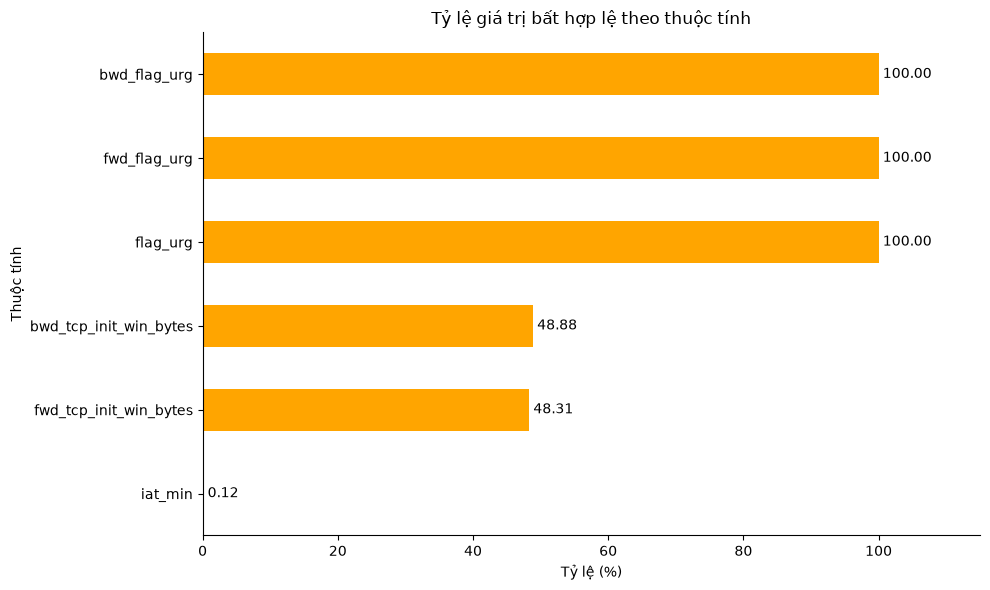

In [24]:
# Tỷ lệ giá trị bất hợp lệ theo thuộc tính
plot_data = invalid_table[invalid_table['Số bản ghi'] > 0].sort_values('Tỷ lệ (%)')

ax = plot_data.plot.barh(
    x='Thuộc tính',
    y='Tỷ lệ (%)',
    figsize=(10, 6),
    legend=False,
    color='orange'
)

ax.set_title('Tỷ lệ giá trị bất hợp lệ theo thuộc tính')
ax.set_xlabel('Tỷ lệ (%)')
ax.set_ylabel('Thuộc tính')
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
ax.margins(x=0.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [25]:
# Outlier theo IQR trên các cột không âm; chỉ để biết mức độ, không xóa tự động
df_plot = df_raw.sample(n=min(SAMPLE_PLOT, len(df_raw)), random_state=RANDOM_STATE)
print('Số dòng lấy mẫu để vẽ và kiểm định:', len(df_plot))

q1 = df_plot[nonnegative_cols].quantile(0.25)
q3 = df_plot[nonnegative_cols].quantile(0.75)
iqr = q3 - q1

outlier_rate = (
    (df_plot[nonnegative_cols].lt(q1 - 1.5 * iqr) | df_plot[nonnegative_cols].gt(q3 + 1.5 * iqr))
    .mean() * 100
).round(3)

outlier_table = outlier_rate.sort_values(ascending=False).rename('Tỷ lệ ngoài IQR (%)').to_frame()

print('Số cột có hơn 10% giá trị ngoài IQR:', int(outlier_rate.gt(10).sum()), '/', len(nonnegative_cols))
outlier_table.head(15)

Số dòng lấy mẫu để vẽ và kiểm định: 200000


Số cột có hơn 10% giá trị ngoài IQR: 46 / 73


,Tỷ lệ ngoài IQR (%)
down_up_ratio,42.546
fwd_iat_max,23.783
fwd_iat_mean,23.027
fwd_iat_tot,22.554
flow_duration,22.432
iat_max,22.198
fwd_iat_std,22.116
bytes_per_s,22.042
iat_std,21.676
bwd_iat_max,21.342


# 04. EDA – Target Distribution

Ưu tiên vì đồ án có bài toán Classification. Xem xét cả nhãn gốc 14 lớp và nhãn nhị phân.

In [26]:
# Thống kê mô tả
df_raw[['label']].describe()

,label
count,1837498
unique,14
top,benign
freq,1395675


In [27]:
# Phân bố nhãn
label_table = df_raw['label'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
label_table['percent'] = (label_table['count'] / len(df_raw) * 100).round(3)

label_table

,label,count,percent
0,benign,1395675,75.955
1,portscan,160106,8.713
2,dos_hulk,158988,8.652
3,ddos,95683,5.207
4,dos_goldeneye,6765,0.368
5,dos_slowloris,5674,0.309
6,dos_slowhttptest,4866,0.265
7,ftp_patator,4003,0.218
8,ssh_patator,2959,0.161
9,webattack_bruteforce,1360,0.074


In [28]:
# Phân bố nhãn nhị phân
attack_table = df_raw['is_attack'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
attack_table['percent'] = (attack_table['count'] / len(df_raw) * 100).round(3)
attack_table['label'] = attack_table['label'].map({0: 'safe', 1: 'attack'})

attack_table

,label,count,percent
0,safe,1395675,75.955
1,attack,441823,24.045


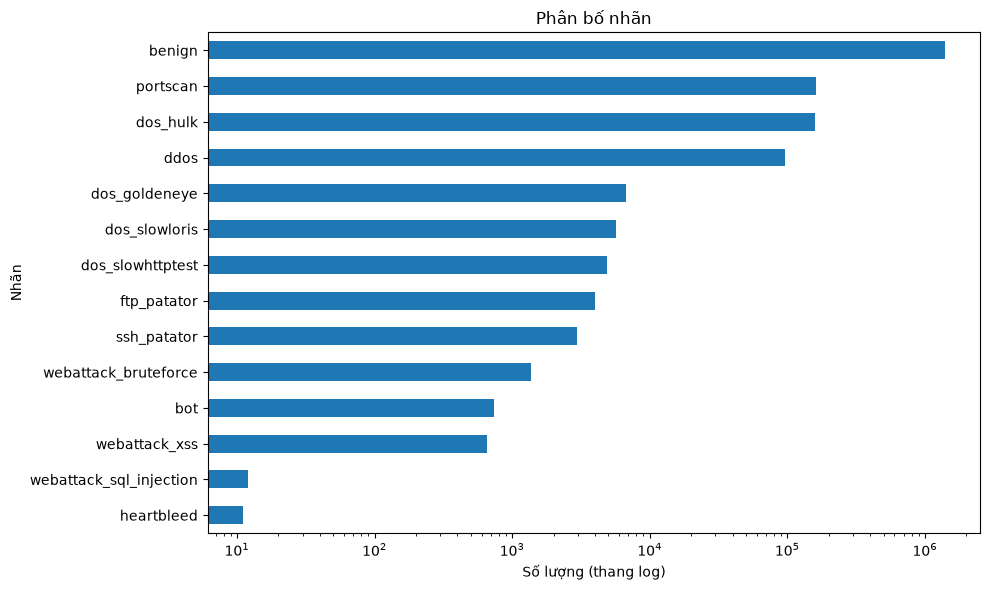

In [29]:
# Kiểm tra phân bổ nhãn
ax = label_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

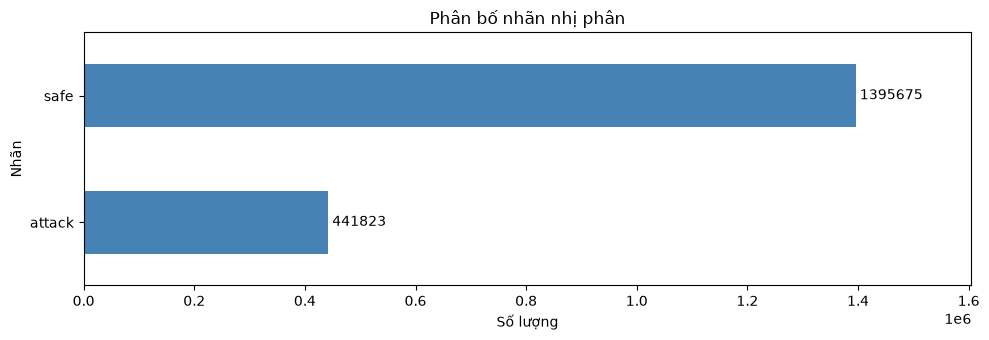

In [30]:
# Kiểm tra phân bổ nhãn nhị phân
ax = attack_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 3.5),
    legend=False,
    color='steelblue'
)

ax.set_title('Phân bố nhãn nhị phân')
ax.set_xlabel('Số lượng')
ax.set_ylabel('Nhãn')
ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

In [31]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(label_table))
print("Lớp nhiều nhất:", label_table.iloc[0]['label'], "-", label_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", label_table.iloc[-1]['label'], "-", label_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(label_table['count'].max() / label_table['count'].min(), 1))

Số lớp: 14
Lớp nhiều nhất: benign - 1395675 mẫu
Lớp ít nhất: heartbleed - 11 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 126879.5


In [32]:
# Kiểm tra cân bằng lớp nhị phân
print("Số lớp:", len(attack_table))
print("Lớp nhiều nhất:", attack_table.iloc[0]['label'], "-", attack_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", attack_table.iloc[-1]['label'], "-", attack_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(attack_table['count'].max() / attack_table['count'].min(), 1))

Số lớp: 2
Lớp nhiều nhất: safe - 1395675 mẫu
Lớp ít nhất: attack - 441823 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.2


In [33]:
# Nhãn theo ngày thu thập - các ngày chạy kịch bản tấn công khác nhau
label_by_day = pd.crosstab(df_raw['label'], df_raw['source_day'])

label_by_day

source_day,Friday,Monday,Thursday,Tuesday,Wednesday
label,,,,,
benign,286438,367181,110448,312675,318933
bot,735,0,0,0,0
ddos,95683,0,0,0,0
dos_goldeneye,0,0,0,0,6765
dos_hulk,0,0,0,0,158988
dos_slowhttptest,0,0,0,0,4866
dos_slowloris,0,0,0,0,5674
ftp_patator,0,0,0,4003,0
heartbleed,0,0,0,0,11


Nhãn nhị phân lệch khoảng 3,2 : 1 (an toàn nhiều hơn tấn công), còn nhãn 14 lớp lệch rất mạnh:
`heartbleed` chỉ có vài chục luồng. Vì vậy **Accuracy một mình không đủ** để đánh giá mô hình ở
giai đoạn sau; phải báo cáo thêm F1-score, Precision và Recall của lớp tấn công.

Bảng nhãn theo ngày cho thấy mỗi ngày thu thập ứng với một nhóm kịch bản tấn công riêng. Đây là lý do
`source_day` nhìn thì liên quan mạnh đến nhãn nhưng thực chất là **thông tin lịch thu thập**, sẽ bị
loại ở mục 10 để tránh rò rỉ.

# 05. EDA – Feature Distribution

Không vẽ hết 83 cột. Chọn 6 thuộc tính numeric tiêu biểu theo vai trò nghiệp vụ (thời lượng, kích
thước gói hai chiều, tốc độ, nhịp gói, số gói) và 2 thuộc tính phân loại.

In [34]:
# Kiểm tra lệch - tính trên mẫu
skew_table = pd.DataFrame({
    'Skew gốc': df_plot[numeric_cols].skew(),
    'Skew log': np.log1p(df_plot[numeric_cols].clip(lower=0)).skew()
}).round(4).sort_values('Skew gốc', ascending=False)

print('Số cột có skew > 5:', int(skew_table['Skew gốc'].gt(5).sum()), '/', len(numeric_cols))
skew_table.head(15)

Số cột có skew > 5: 51 / 79


,Skew gốc,Skew log
fwd_subflow_bytes_mean,355.2886,-0.8471
fwd_pkt_len_tot,302.8039,-0.5954
bwd_bulk_pkt_mean,282.5944,2.8136
bwd_bulk_bytes_mean,279.1407,2.0736
bwd_subflow_pkt_mean,216.9353,2.0045
fwd_subflow_pkt_mean,212.5956,2.4044
bwd_subflow_bytes_mean,206.1383,-0.4294
bwd_non_empty_pkt_cnt,176.9078,1.8600
bwd_pkt_cnt,176.8995,1.6882
bwd_pkt_hdr_len_tot,176.3936,0.6293


In [35]:
# 6 thuộc tính numeric tiêu biểu và 2 thuộc tính phân loại
focus_num = [
    'flow_duration', 'pkt_len_mean', 'bwd_pkt_len_mean',
    'bytes_per_s', 'iat_mean', 'fwd_pkt_cnt'
]
focus_cat = ['ip_prot', 'source_day']

df_plot[focus_num].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
flow_duration,200000.0,1.196003e+07,3.089069e+07,0.0,315.000,61980.500,1448904.750,1.200000e+08
pkt_len_mean,200000.0,3.051510e+02,4.620240e+02,0.0,53.000,84.500,274.588,2.323000e+03
bwd_pkt_len_mean,200000.0,4.753040e+02,7.370950e+02,0.0,61.000,122.000,457.552,3.877333e+03
bytes_per_s,200000.0,5.927858e+05,7.946178e+06,0.0,232.710,5681.579,81909.009,1.983000e+09
iat_mean,200000.0,8.763505e+05,3.439218e+06,0.0,104.333,20344.762,185469.714,6.599936e+07
fwd_pkt_cnt,200000.0,1.362600e+01,1.103494e+03,0.0,2.000,2.000,5.000,2.177960e+05


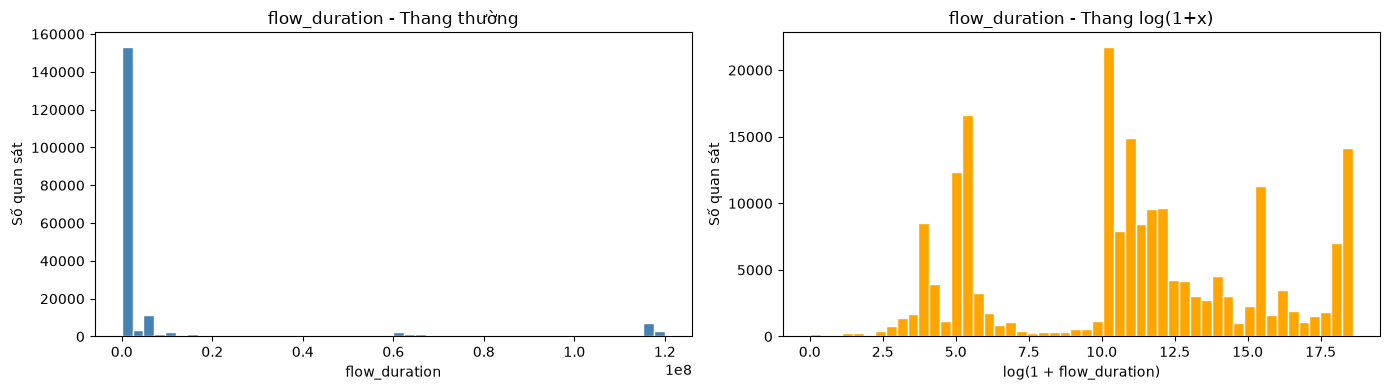

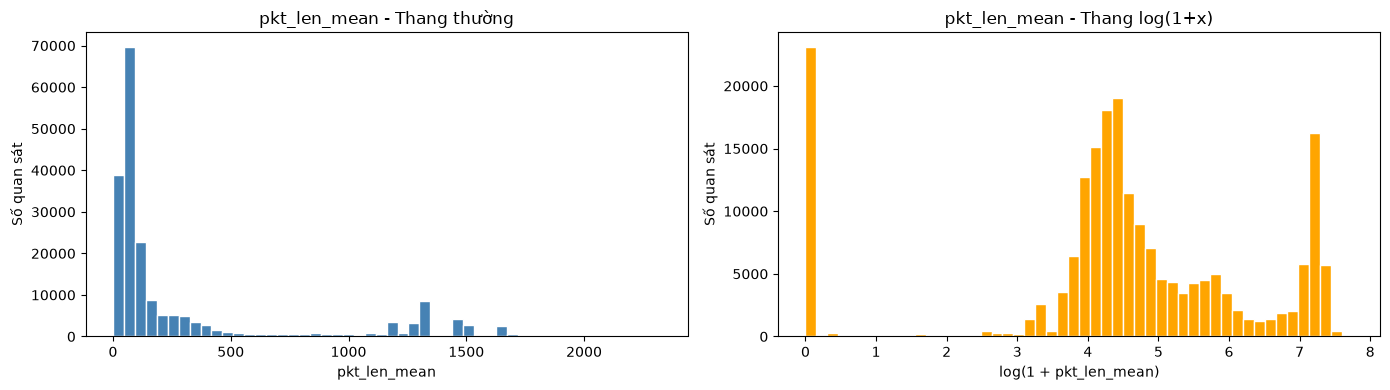

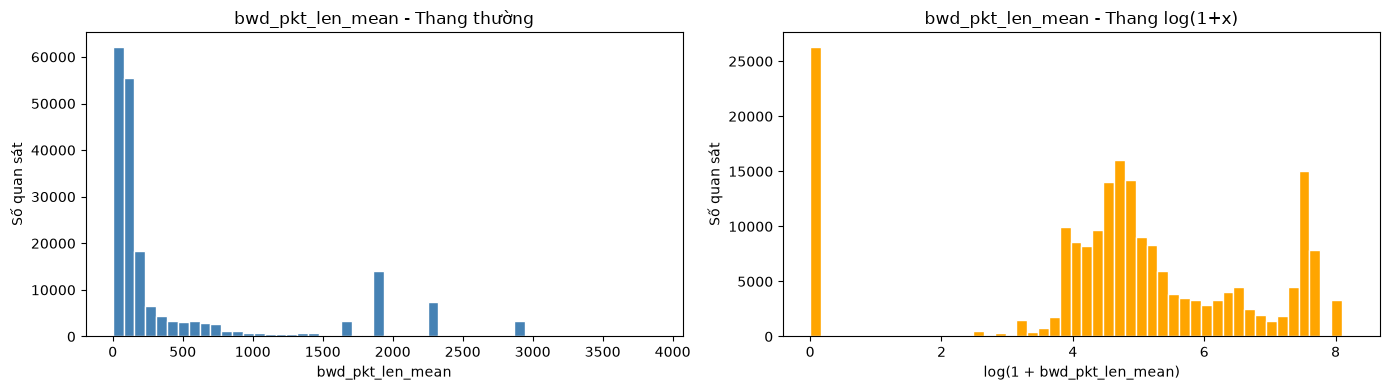

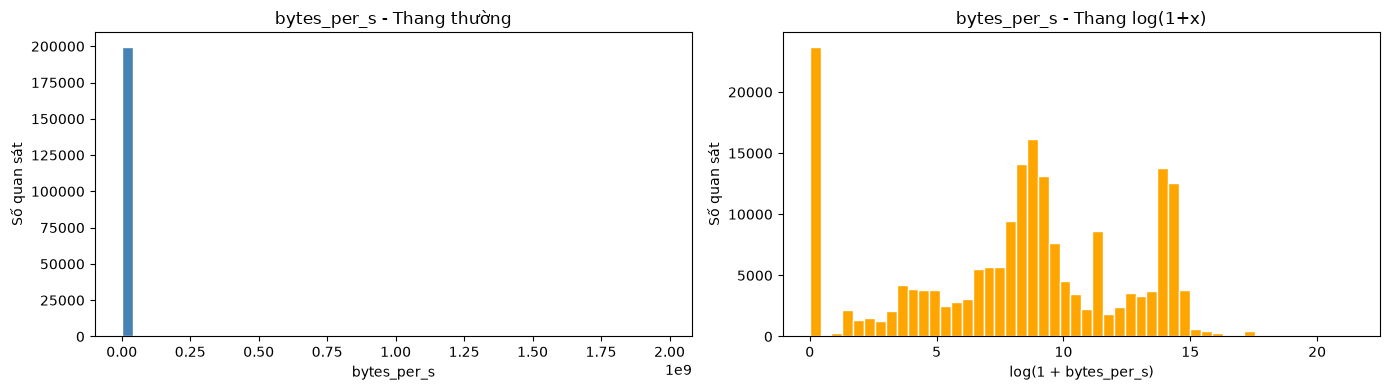

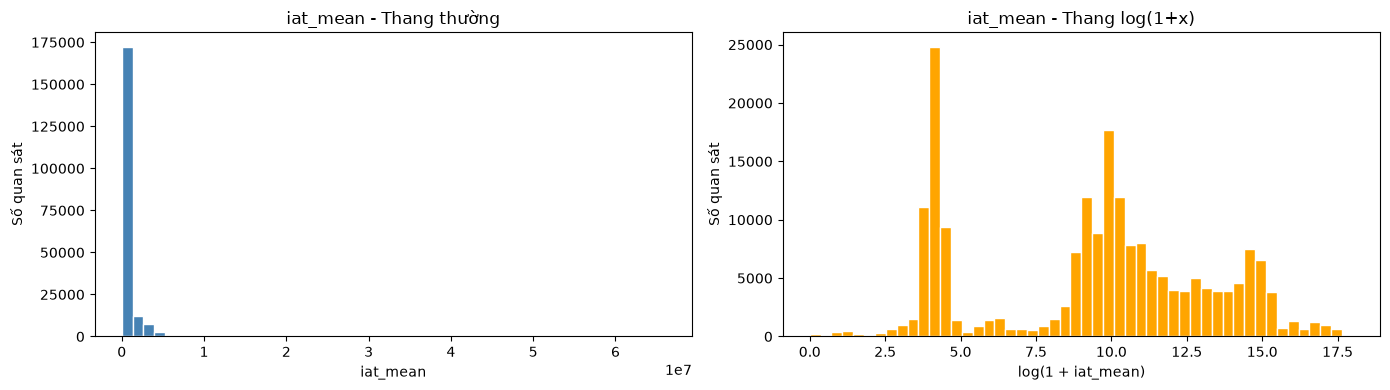

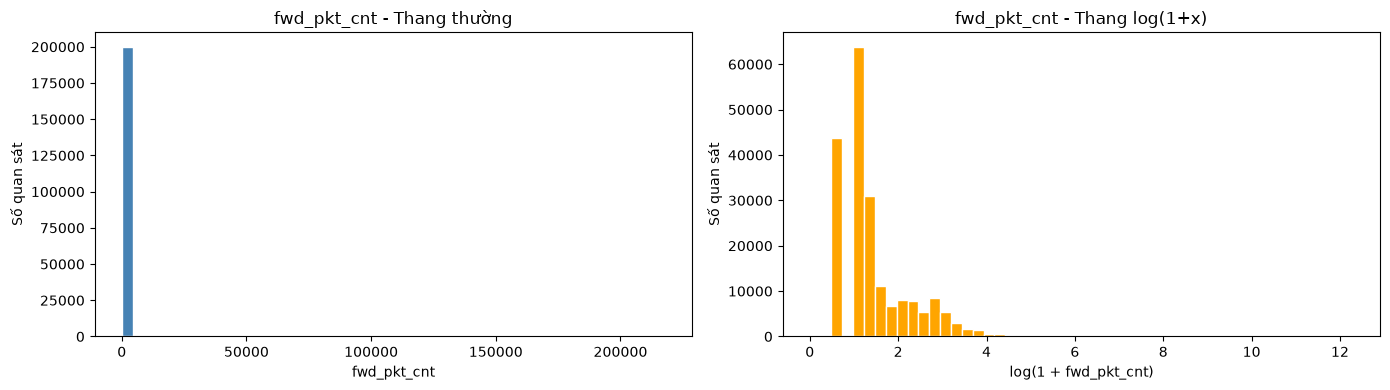

In [36]:
# Vẽ histogram trên thang thường và thang log(1+x)
for col in focus_num:
    data = df_plot[col].replace([np.inf, -np.inf], np.nan).dropna()
    data_log = data[data >= 0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].hist(data, bins=50, color='steelblue', edgecolor='white')
    axes[0].set_title(f'{col} - Thang thường')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Số quan sát')

    axes[1].hist(np.log1p(data_log), bins=50, color='orange', edgecolor='white')
    axes[1].set_title(f'{col} - Thang log(1+x)')
    axes[1].set_xlabel(f'log(1 + {col})')
    axes[1].set_ylabel('Số quan sát')

    plt.tight_layout()
    plt.show()

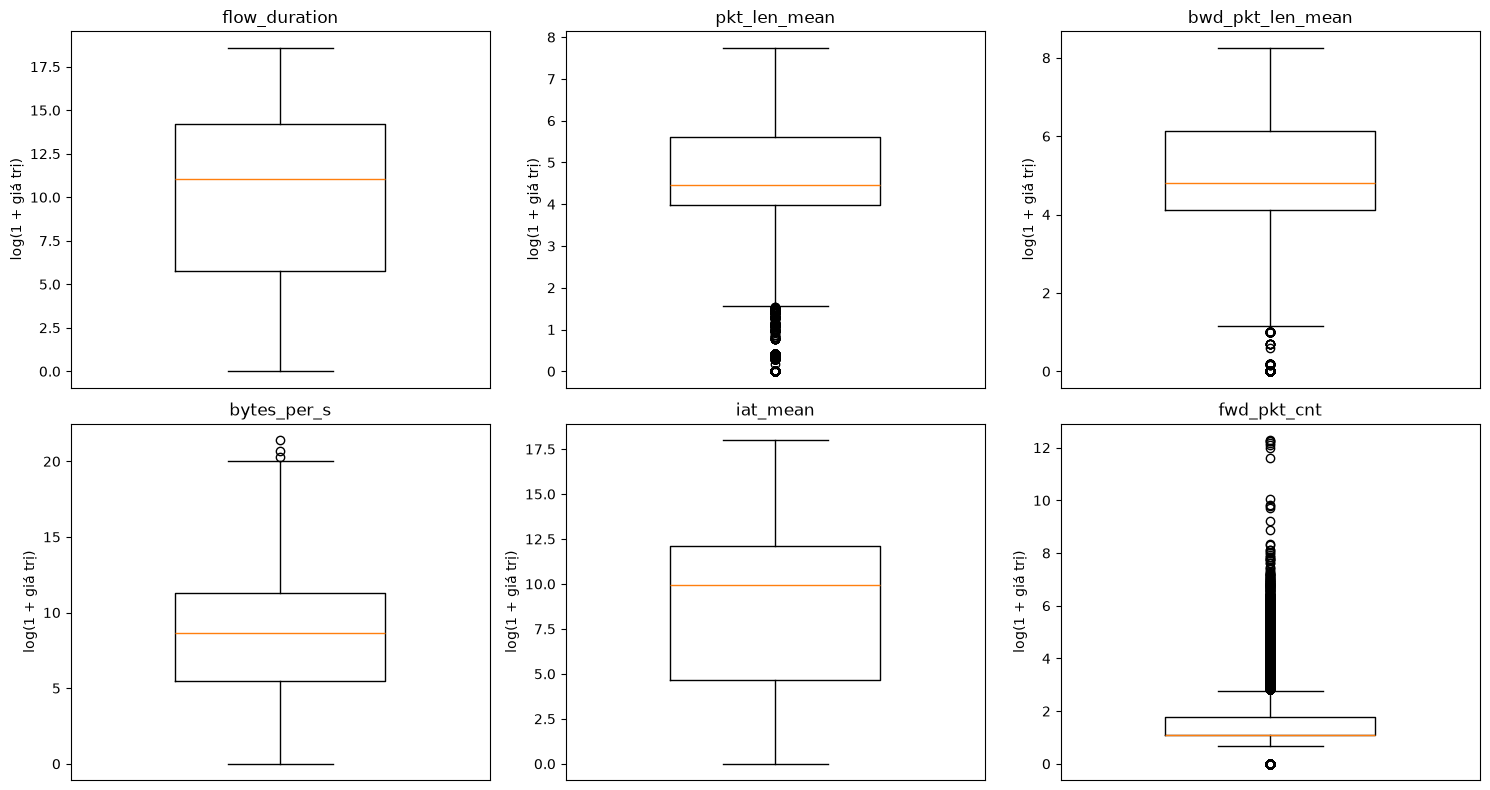

In [37]:
# Boxplot trên thang log(1+x) để thấy độ phân tán và outlier
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), focus_num):
    data = df_plot[col].clip(lower=0).dropna()
    ax.boxplot(np.log1p(data), widths=0.5)
    ax.set_title(col)
    ax.set_ylabel('log(1 + giá trị)')
    ax.set_xticks([])

plt.tight_layout()
plt.show()

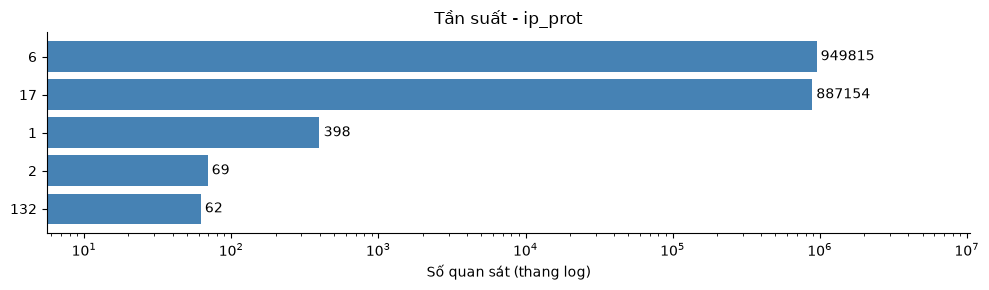

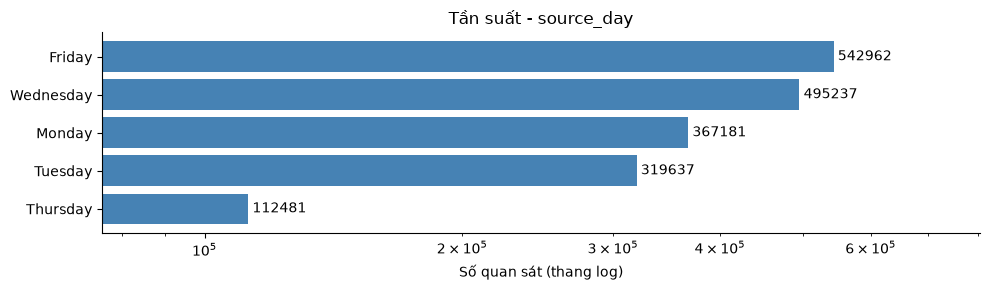

In [38]:
# Tần suất các biến phân loại
for col in focus_cat:
    counts = df_raw[col].value_counts(dropna=False).sort_values()

    fig, ax = plt.subplots(figsize=(10, max(3, 0.45 * len(counts))))
    ax.barh(counts.index.astype(str), counts.to_numpy(), color='steelblue')
    ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)
    ax.set_title(f'Tần suất - {col}')
    ax.set_xlabel('Số quan sát (thang log)')
    ax.set_xscale('log')
    ax.margins(x=0.25)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

In [39]:
# Bảng tần suất - phát hiện nhóm hiếm
freq_table = pd.concat([
    df_raw[col]
    .value_counts(dropna=False)
    .rename_axis('Giá trị')
    .reset_index(name='count')
    .assign(**{'Thuộc tính': col})
    for col in focus_cat
])
freq_table['percent'] = (freq_table['count'] / len(df_raw) * 100).round(3)
freq_table = freq_table[['Thuộc tính', 'Giá trị', 'count', 'percent']]

freq_table

,Thuộc tính,Giá trị,count,percent
0,ip_prot,6,949815,51.691
1,ip_prot,17,887154,48.281
2,ip_prot,1,398,0.022
3,ip_prot,2,69,0.004
4,ip_prot,132,62,0.003
0,source_day,Friday,542962,29.549
1,source_day,Wednesday,495237,26.952
2,source_day,Monday,367181,19.983
3,source_day,Tuesday,319637,17.395
4,source_day,Thursday,112481,6.121


In [40]:
# dst_port có hơn 60 nghìn giá trị phân biệt nên chỉ xem 15 cổng phổ biến nhất
port_table = df_raw['dst_port'].value_counts().head(15).rename_axis('dst_port').reset_index(name='count')
port_table['percent'] = (port_table['count'] / len(df_raw) * 100).round(3)

port_table

,dst_port,count,percent
0,53,848618,46.183
1,80,419359,22.822
2,443,342979,18.666
3,123,22692,1.235
4,22,7722,0.420
5,137,6900,0.376
6,21,6386,0.348
7,389,4382,0.238
8,88,3344,0.182
9,3268,2226,0.121


# 06. EDA – Feature vs Target

Tìm thuộc tính có khả năng hỗ trợ phân lớp. Đây chỉ là đánh giá khám phá, chưa kết luận giữ/loại.
Việc lựa chọn chính thức làm ở mục 09–10 và chỉ học trên tập train.

## Numeric – Target

In [41]:
def analyze_category_vs_continous(category_var, continous_var, df):
    lst = []
    for name, g in df.groupby(category_var):
        lst.append(g[continous_var])
    f_statistic, p_value = f_oneway(*lst)
    return f_statistic, p_value

In [42]:
# Kiểm định ANOVA giữa từng thuộc tính numeric và biến mục tiêu
anova_cols = [col for col in numeric_cols if col not in constant_cols + ['timestamp']]
anova_rows = []

for col in anova_cols:
    f_statistic, p_value = analyze_category_vs_continous(target_col, col, df_plot)
    anova_rows.append([col, f_statistic, p_value])

anova_table = pd.DataFrame(anova_rows, columns=['Thuộc tính', 'F statistic', 'p-value'])
anova_table['Có tác động (alpha=0.05)'] = np.where(anova_table['p-value'] < 0.05, 'Có', 'Không')
anova_table = anova_table.sort_values('F statistic', ascending=False).reset_index(drop=True)

dep = anova_table.loc[anova_table['p-value'].lt(0.05), 'Thuộc tính'].tolist()
indepen = anova_table.loc[~anova_table['p-value'].lt(0.05), 'Thuộc tính'].tolist()

print(f'Số biến có tác động đến {target_col}: {len(dep)}')
print(f'Các biến không có tác động đến {target_col}: {indepen}')
anova_table.head(15)

Số biến có tác động đến is_attack: 69
Các biến không có tác động đến is_attack: ['fwd_subflow_pkt_mean', 'bwd_bulk_pkt_mean', 'bwd_pkt_len_tot', 'bwd_subflow_pkt_mean', 'bwd_subflow_bytes_mean', 'bwd_bulk_bytes_mean']


,Thuộc tính,F statistic,p-value,Có tác động (alpha=0.05)
0,pkt_len_std,117783.211522,0.0,Có
1,pkt_len_mean,116405.031021,0.0,Có
2,bwd_pkt_len_std,114900.105107,0.0,Có
3,fwd_pkt_hdr_len_min,112862.058594,0.0,Có
4,bwd_pkt_len_mean,108635.922597,0.0,Có
5,bwd_pkt_len_max,105805.232276,0.0,Có
6,pkt_len_max,100322.052791,0.0,Có
7,pkt_len_var,96190.612350,0.0,Có
8,ip_prot,82533.713783,0.0,Có
9,down_up_ratio,80877.512275,0.0,Có


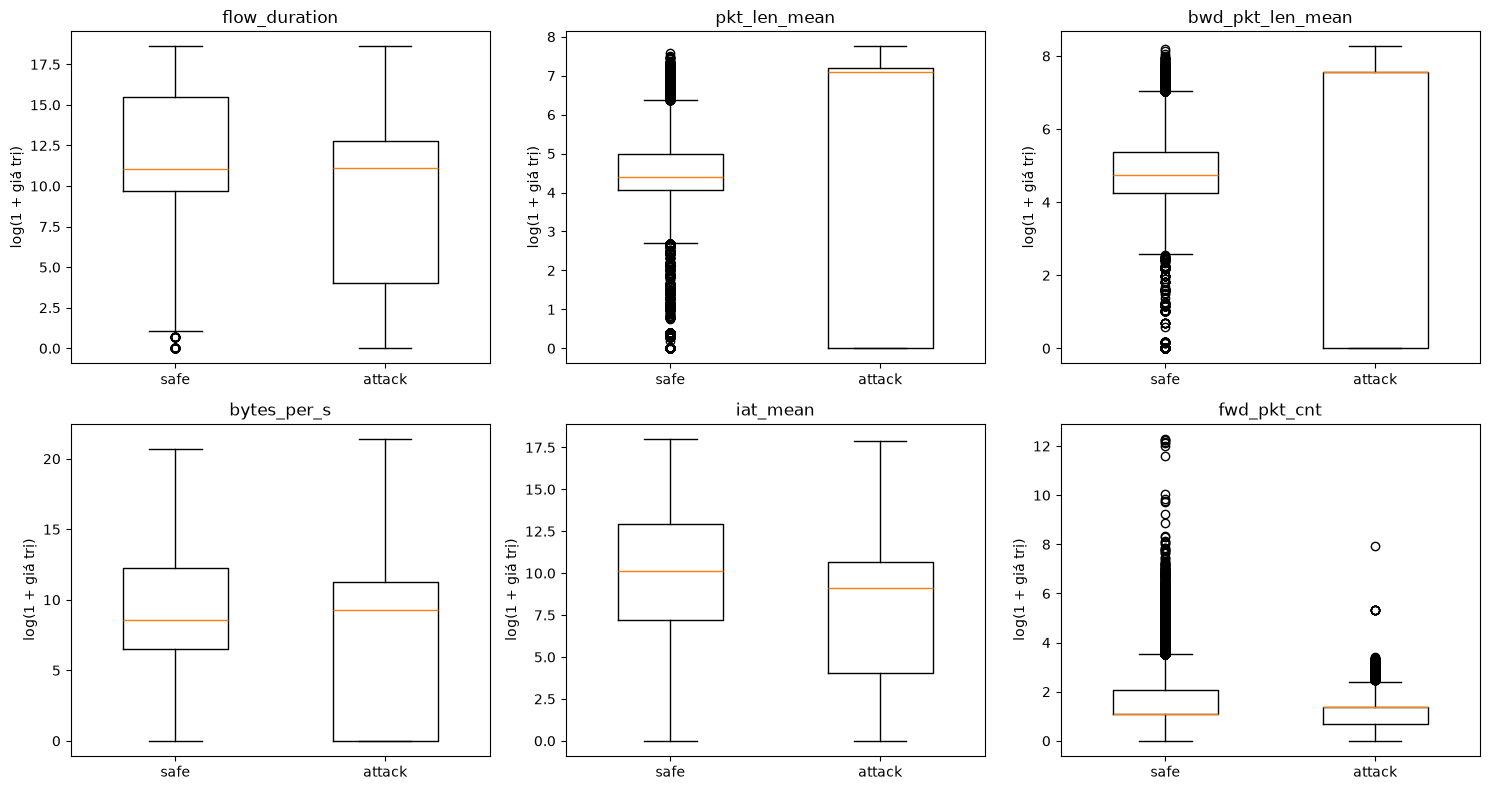

In [43]:
# Boxplot theo lớp: hai lớp có khác nhau về phân bố không?
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), focus_num):
    groups = [
        np.log1p(df_plot.loc[df_plot[target_col].eq(value), col].clip(lower=0).dropna())
        for value in [0, 1]
    ]
    ax.boxplot(groups, tick_labels=['safe', 'attack'], widths=0.5)
    ax.set_title(col)
    ax.set_ylabel('log(1 + giá trị)')

plt.tight_layout()
plt.show()

## Categorical – Target

In [44]:
# Crosstab và tỷ lệ tấn công của từng nhóm
for col in focus_cat:
    table = pd.crosstab(df_raw[col], df_raw[target_col])
    table.columns = ['safe', 'attack']
    table['total'] = table.sum(axis=1)
    table['attack_rate (%)'] = (table['attack'] / table['total'] * 100).round(3)

    print('* ' * 40)
    display(table.sort_values('total', ascending=False))

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


,safe,attack,total,attack_rate (%)
ip_prot,,,,
6,507992,441823,949815,46.517
17,887154,0,887154,0.000
1,398,0,398,0.000
2,69,0,69,0.000
132,62,0,62,0.000


* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 


,safe,attack,total,attack_rate (%)
source_day,,,,
Friday,286438,256524,542962,47.245
Wednesday,318933,176304,495237,35.600
Monday,367181,0,367181,0.000
Tuesday,312675,6962,319637,2.178
Thursday,110448,2033,112481,1.807


In [45]:
# Tỷ lệ tấn công theo 15 cổng đích phổ biến nhất
top_ports = df_raw['dst_port'].value_counts().head(15).index
mask = df_raw['dst_port'].isin(top_ports)

port_target = pd.crosstab(df_raw.loc[mask, 'dst_port'], df_raw.loc[mask, target_col])
port_target.columns = ['safe', 'attack']
port_target['total'] = port_target.sum(axis=1)
port_target['attack_rate (%)'] = (port_target['attack'] / port_target['total'] * 100).round(3)

port_target.sort_values('total', ascending=False)

,safe,attack,total,attack_rate (%)
dst_port,,,,
53,848458,160,848618,0.019
80,145037,274322,419359,65.415
443,342738,241,342979,0.070
123,22692,0,22692,0.000
22,4520,3202,7722,41.466
137,6900,0,6900,0.000
21,2139,4247,6386,66.505
389,4222,160,4382,3.651
88,3184,160,3344,4.785


## Numeric – Numeric

In [46]:
def analyze_continous_vs_continous(var_1, var_2, df):
    # Calculate Pearson correlation coefficient
    correlation_coefficient, p_value = stats.pearsonr(df[var_1], df[var_2])
    print('var 1=', var_1, ',', 'var 2=', var_2)
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.2f} - P-value: {p_value:.4f}")
    sns.scatterplot(data=df, x=var_1, y=var_2)
    plt.show()

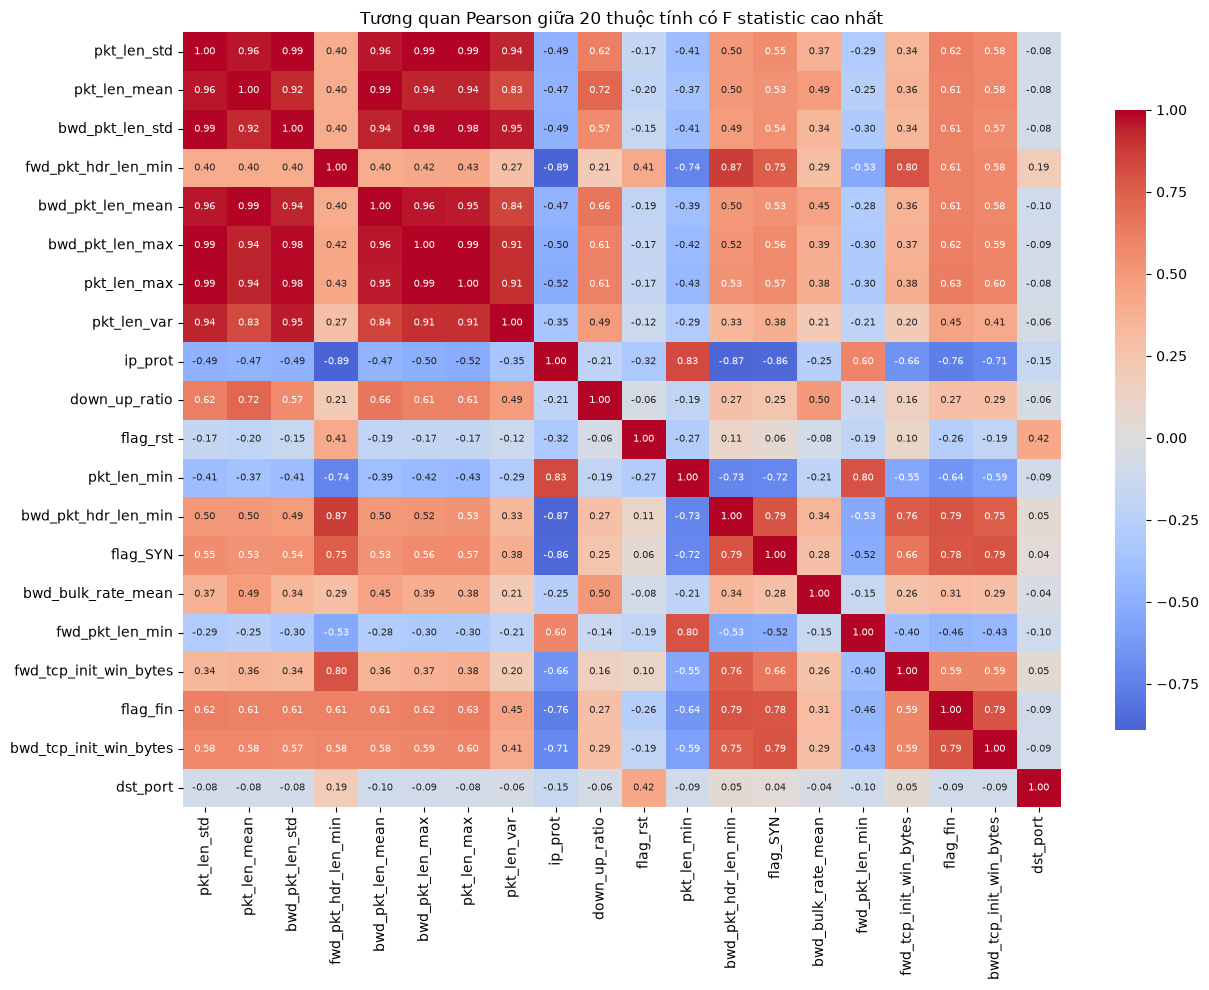

In [47]:
# Tương quan giữa 20 thuộc tính có F statistic cao nhất
corr_cols = anova_table['Thuộc tính'].head(20).tolist()
corr = df_plot[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Tương quan Pearson giữa 20 thuộc tính có F statistic cao nhất')

plt.tight_layout()
plt.show()

In [48]:
# Các cặp thuộc tính gần như trùng nhau
corr_all = df_plot[anova_cols].corr().abs()
upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))

pairs = (
    upper.stack()
    .rename('|r|')
    .reset_index()
    .set_axis(['Thuộc tính 1', 'Thuộc tính 2', '|r|'], axis=1)
)
redundant_pairs = pairs[pairs['|r|'] >= 0.95].sort_values('|r|', ascending=False).reset_index(drop=True)

print('Số cặp có |r| >= 0.95:', len(redundant_pairs))
redundant_pairs.head(20)

Số cặp có |r| >= 0.95: 56


,Thuộc tính 1,Thuộc tính 2,|r|
0,bwd_pkt_cnt,bwd_non_empty_pkt_cnt,0.999996
1,bwd_pkt_cnt,bwd_pkt_hdr_len_tot,0.999757
2,bwd_pkt_hdr_len_tot,bwd_non_empty_pkt_cnt,0.999744
3,bwd_pkt_cnt,flag_ack,0.999608
4,bwd_non_empty_pkt_cnt,flag_ack,0.999607
5,fwd_pkt_cnt,fwd_pkt_hdr_len_tot,0.999578
6,bwd_pkt_hdr_len_tot,flag_ack,0.999363
7,fwd_pkt_cnt,flag_ack,0.999343
8,fwd_pkt_hdr_len_tot,flag_ack,0.999073
9,fwd_subflow_pkt_mean,bwd_subflow_pkt_mean,0.999054


## Feature – Target bằng Mutual Information

In [49]:
# Mutual Information mang tính khám phá; bản chính thức học trên tập train ở mục 09
mi_explore_sample = df_plot.sample(n=min(50_000, len(df_plot)), random_state=RANDOM_STATE)
mi_explore_cols = [col for col in anova_cols]

mi_explore_X = (
    mi_explore_sample[mi_explore_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

mi_explore = mutual_info_classif(
    mi_explore_X,
    mi_explore_sample[target_col],
    discrete_features=[col in discrete_cols for col in mi_explore_cols],
    random_state=RANDOM_STATE
)

mi_explore_table = pd.DataFrame({
    'Thuộc tính': mi_explore_cols,
    'MI Score': mi_explore
}).sort_values('MI Score', ascending=False).reset_index(drop=True)

mi_explore_table.head(15)

,Thuộc tính,MI Score
0,bwd_pkt_len_mean,0.463655
1,bwd_subflow_bytes_mean,0.461651
2,bwd_pkt_len_tot,0.459866
3,pkt_len_mean,0.453950
4,pkt_len_max,0.443681
5,pkt_len_var,0.437456
6,pkt_len_std,0.437447
7,bwd_pkt_len_max,0.430687
8,fwd_pkt_hdr_len_tot,0.415321
9,flag_ack,0.402885


# 07. EDA – Findings

Chỉ giữ những hàng tương ứng với phát hiện thực sự xuất hiện trong dữ liệu. Bằng chứng lấy trực tiếp
từ các biến đã tính ở trên, không ghi số liệu bằng tay.

In [50]:
# Bảng tổng hợp phát hiện EDA
# Chỉ cộng giá trị thực sự sai miền; không cộng các cột hằng vì đó là vấn đề ở mức cột
n_invalid_raw = int(
    invalid_table.loc[~invalid_table['Vấn đề'].str.startswith('Thuộc tính hằng'), 'Số bản ghi'].sum()
)
n_skew = int(skew_table['Skew gốc'].gt(5).sum())
n_weak_mi = int(mi_explore_table['MI Score'].lt(0.01).sum())
flow_id_unique = nunique_raw['flow_id'] / len(df_raw) * 100

findings = [
    [
        'Dữ liệu đầy đủ: không thiếu, không vô cực, không trùng toàn bộ cột',
        f'null = {n_null_raw}, inf = {inf_count}, duplicated = {n_dup_all}',
        'Không cần điền khuyết ở bước này'
    ],
    [
        'Có bản ghi trùng khi bỏ qua flow_id và timestamp',
        f'{n_dup_content:,} dòng ({n_dup_content / len(df_raw) * 100:.2f}%)',
        'Không xóa: đây là các luồng khác nhau trùng đặc trưng, chỉ ghi nhận'
    ],
    [
        'Có thuộc tính hằng',
        f'{constant_cols}',
        'Loại khỏi mô hình vì không phân biệt được lớp'
    ],
    [
        'iat_min có giá trị âm trong khi là đại lượng thời gian',
        f"{int(df_raw['iat_min'].lt(0).sum()):,} dòng",
        'Đánh dấu thiếu rồi điền bằng median của tập train'
    ],
    [
        'Hai cột cửa sổ TCP dùng -1 làm mã không ghi nhận',
        f"fwd = {int(df_raw['fwd_tcp_init_win_bytes'].eq(-1).sum()):,}, "
        f"bwd = {int(df_raw['bwd_tcp_init_win_bytes'].eq(-1).sum()):,}",
        'Đổi -1 thành thiếu, thêm cờ chỉ báo để không mất thông tin'
    ],
    [
        'Phân bố lệch phải rất mạnh ở phần lớn thuộc tính',
        f'{n_skew}/{len(numeric_cols)} cột có skew > 5',
        'Dùng log(1+x) khi vẽ; rời rạc hóa theo phân vị cho khai phá luật'
    ],
    [
        'Rất nhiều giá trị ngoài khoảng IQR',
        f"{int(outlier_rate.gt(10).sum())}/{len(nonnegative_cols)} cột có hơn 10% điểm ngoài IQR",
        'Không xóa: lưu lượng mạng lệch tự nhiên, outlier chính là dấu hiệu tấn công'
    ],
    [
        'Lớp không cân bằng',
        f"nhị phân {attack_table['count'].max() / attack_table['count'].min():.1f} : 1, "
        f"14 lớp {label_table['count'].max() / label_table['count'].min():.0f} : 1",
        'Báo cáo thêm F1, Precision, Recall; không dùng Accuracy một mình'
    ],
    [
        'Có thuộc tính định danh và thuộc tính rò rỉ thông tin',
        f'flow_id có {flow_id_unique:.1f}% giá trị phân biệt; src_addr, dst_addr, timestamp, source_day gắn với hạ tầng và lịch thu thập',
        'Loại khỏi mô hình ở mục 10'
    ],
    [
        'Nhiều thuộc tính trùng lặp thông tin',
        f'{len(redundant_pairs)} cặp có |r| >= 0.95',
        'Đánh dấu dư thừa, thử nghiệm bằng mô hình trước khi loại'
    ],
    [
        'Một số thuộc tính liên quan rất yếu với nhãn',
        f'{n_weak_mi} thuộc tính có MI < 0,01',
        'Đưa vào nhóm thử nghiệm, không loại chỉ vì dưới ngưỡng'
    ],
]

findings_table = pd.DataFrame(findings, columns=['Phát hiện', 'Bằng chứng', 'Hướng xử lý'])
findings_table.to_csv(OUT_DIR / 'eda_findings.csv', index=False)

findings_table

,Phát hiện,Bằng chứng,Hướng xử lý
0,"Dữ liệu đầy đủ: không thiếu, không vô cực, khô...","null = 0, inf = 0, duplicated = 0",Không cần điền khuyết ở bước này
1,Có bản ghi trùng khi bỏ qua flow_id và timestamp,"4,805 dòng (0.26%)",Không xóa: đây là các luồng khác nhau trùng đặ...
2,Có thuộc tính hằng,"['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']",Loại khỏi mô hình vì không phân biệt được lớp
3,iat_min có giá trị âm trong khi là đại lượng t...,"2,270 dòng",Đánh dấu thiếu rồi điền bằng median của tập train
4,Hai cột cửa sổ TCP dùng -1 làm mã không ghi nhận,"fwd = 887,683, bwd = 898,080","Đổi -1 thành thiếu, thêm cờ chỉ báo để không m..."
5,Phân bố lệch phải rất mạnh ở phần lớn thuộc tính,51/79 cột có skew > 5,Dùng log(1+x) khi vẽ; rời rạc hóa theo phân vị...
6,Rất nhiều giá trị ngoài khoảng IQR,46/73 cột có hơn 10% điểm ngoài IQR,"Không xóa: lưu lượng mạng lệch tự nhiên, outli..."
7,Lớp không cân bằng,"nhị phân 3.2 : 1, 14 lớp 126880 : 1","Báo cáo thêm F1, Precision, Recall; không dùng..."
8,Có thuộc tính định danh và thuộc tính rò rỉ th...,"flow_id có 51.3% giá trị phân biệt; src_addr, ...",Loại khỏi mô hình ở mục 10
9,Nhiều thuộc tính trùng lặp thông tin,56 cặp có |r| >= 0.95,"Đánh dấu dư thừa, thử nghiệm bằng mô hình trướ..."


# 08. Preprocess – Data Cleaning

Triển khai theo đúng bảng phát hiện ở mục 07. Mỗi bước ghi lại số dòng bị loại, số cột bị loại và
số giá trị được xử lý vào `clean_log`; chi tiết theo từng cột vào `issue_log`.

Nguyên tắc: **chỉ đánh dấu thiếu ở bước này, việc điền khuyết để sau khi chia train/test** (mục 11)
để không học thống kê từ tập test.

In [51]:
clean_log = []
issue_log = []

df_clean = df_raw.copy()
print('Trước làm sạch:', df_clean.shape)

Trước làm sạch: (1837498, 85)


In [52]:
# 1. Loại dòng trùng toàn bộ cột
duplicate_mask = df_clean.duplicated()
n_duplicate = int(duplicate_mask.sum())
df_clean = df_clean.loc[~duplicate_mask].copy()

clean_log.append([
    'Loại trùng toàn bộ cột', n_duplicate, 0, 0,
    'Bản ghi lặp hoàn toàn không mang thêm thông tin'
])

print('Số dòng loại:', n_duplicate, '- còn lại:', len(df_clean))

Số dòng loại: 0 - còn lại: 1837498


In [53]:
# 2. Loại dòng thiếu nhãn - không có biến mục tiêu thì không dùng được
missing_label = df_clean[label_col].isna() | df_clean[label_col].astype('string').str.strip().eq('')
n_missing_label = int(missing_label.sum())
df_clean = df_clean.loc[~missing_label].copy()

clean_log.append([
    'Loại dòng thiếu nhãn', n_missing_label, 0, 0,
    'Không có biến mục tiêu nên không thể dùng cho học có giám sát'
])

print('Số dòng thiếu nhãn:', n_missing_label, '- còn lại:', len(df_clean))

Số dòng thiếu nhãn: 0 - còn lại: 1837498


In [54]:
# 3. Chuẩn hóa kiểu dữ liệu
# Đổi sang dữ liệu chuỗi
text_cols = ['flow_id', 'src_addr', 'dst_addr', 'label', 'source_day']

n_text_format = 0

for col in text_cols:
    before = df_clean[col].astype('string')
    after = before.str.strip().replace('', pd.NA)
    n_text_format += int((before.fillna('') != after.fillna('')).sum())
    df_clean[col] = after

clean_log.append([
    'Chuẩn hóa văn bản', 0, 0, n_text_format,
    'Xóa khoảng trắng đầu/cuối, chuỗi rỗng đổi thành thiếu'
])
print('Số giá trị văn bản được chuẩn hóa:', n_text_format)

# Chuyển các cột số về đúng kiểu; giá trị không chuyển được thành NaN
# Mã phân loại và timestamp dùng Int64 để giữ dạng số nguyên khi có giá trị thiếu
n_wrong_format = 0

for col in numeric_cols:
    before = df_clean[col]
    after = pd.to_numeric(before, errors='coerce')
    n_bad = int((before.notna() & after.isna()).sum())
    n_wrong_format += n_bad

    if n_bad > 0:
        issue_log.append([col, 'Sai định dạng số', n_bad])

    if col in code_cols + ['timestamp']:
        df_clean[col] = after.astype('Int64')
    else:
        df_clean[col] = after.astype('float64')

clean_log.append([
    'Chuẩn hóa kiểu số', 0, 0, n_wrong_format,
    'Giá trị không chuyển được thành số đổi sang thiếu'
])
print('Số giá trị số không hợp lệ:', n_wrong_format)

Số giá trị văn bản được chuẩn hóa: 0


Số giá trị số không hợp lệ: 0


In [55]:
# 4. Đánh dấu giá trị ngoài miền hợp lệ thành thiếu, không xóa dòng
n_invalid = 0

for col in ['src_port', 'dst_port']:
    bad = (
        df_clean[col].notna()
        & (
            ~df_clean[col].between(0, 65535)
            | df_clean[col].mod(1).ne(0)
        )
    )
    n_bad = int(bad.sum())
    df_clean.loc[bad, col] = pd.NA
    n_invalid += n_bad

    if n_bad > 0:
        issue_log.append([col, 'Cổng ngoài 0–65535 hoặc không nguyên', n_bad])

bad = (
    df_clean['ip_prot'].notna()
    & (
        ~df_clean['ip_prot'].between(0, 255)
        | df_clean['ip_prot'].mod(1).ne(0)
    )
)
n_bad = int(bad.sum())
df_clean.loc[bad, 'ip_prot'] = pd.NA
n_invalid += n_bad

if n_bad > 0:
    issue_log.append(['ip_prot', 'Mã giao thức ngoài 0–255', n_bad])

for col in nonnegative_cols:
    bad = df_clean[col] < 0
    n_bad = int(bad.sum())
    df_clean.loc[bad, col] = np.nan
    n_invalid += n_bad

    if n_bad > 0:
        issue_log.append([col, 'Giá trị âm ở đại lượng không thể âm', n_bad])

clean_log.append([
    'Đánh dấu giá trị bất hợp lý', 0, 0, n_invalid,
    'Giá trị ngoài miền hợp lệ đổi thành thiếu; dòng vẫn giữ vì các cột khác còn dùng được'
])
print('Số giá trị bất hợp lý đã đánh dấu:', n_invalid)

Số giá trị bất hợp lý đã đánh dấu: 2270


In [56]:
# 5. Mã -1 ở cửa sổ TCP nghĩa là không ghi nhận, không phải kích thước âm
# Đổi thành thiếu nhưng thêm cờ chỉ báo để không mất thông tin "luồng không có cửa sổ TCP"
n_sentinel = 0
absent_cols = []

for col in sentinel_cols:
    absent = df_clean[col].eq(-1)
    n_bad = int(absent.sum())

    flag_col = col.replace('_bytes', '_absent')
    df_clean[flag_col] = absent.astype('int8')
    df_clean.loc[absent, col] = np.nan

    absent_cols.append(flag_col)
    n_sentinel += n_bad
    issue_log.append([col, 'Mã -1 (không ghi nhận) đổi thành thiếu', n_bad])

clean_log.append([
    'Tách mã -1 của cửa sổ TCP', 0, 0, n_sentinel,
    f'Thêm cờ chỉ báo {absent_cols} để giữ thông tin'
])

print('Số giá trị -1 đã tách:', n_sentinel)
print('Các cờ chỉ báo đã thêm:', absent_cols)

Số giá trị -1 đã tách: 1785763
Các cờ chỉ báo đã thêm: ['fwd_tcp_init_win_absent', 'bwd_tcp_init_win_absent']


In [57]:
# 6. Loại thuộc tính hằng
df_clean = df_clean.drop(columns=constant_cols)

clean_log.append([
    'Loại thuộc tính hằng', 0, len(constant_cols), 0,
    'Chỉ có 1 giá trị nên không có khả năng phân biệt lớp'
])

print('Các cột đã loại:', constant_cols)
print('Sau làm sạch:', df_clean.shape)

Các cột đã loại: ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']
Sau làm sạch: (1837498, 84)


In [58]:
# 7. Thêm trường thời gian cho kho dữ liệu ở notebook 02
flow_time = pd.to_datetime(df_clean['timestamp'], unit='us', errors='coerce')
df_clean['date'] = flow_time.dt.date.astype('string')
df_clean['hour'] = flow_time.dt.hour.astype('Int64')

print('Khoảng thời gian:', df_clean['date'].min(), '->', df_clean['date'].max())
df_clean[['timestamp', 'date', 'hour']].head()

Khoảng thời gian: 2017-07-03 -> 2017-07-07


,timestamp,date,hour
0,1499428790315195,2017-07-07,11
1,1499428790316273,2017-07-07,11
2,1499428834843793,2017-07-07,12
3,1499428834845380,2017-07-07,12
4,1499428835164943,2017-07-07,12


In [59]:
# Nhật ký tiền xử lý
clean_table = pd.DataFrame(
    clean_log,
    columns=['Công đoạn', 'Số dòng bị loại', 'Số cột bị loại', 'Số giá trị xử lý', 'Lý do']
)

clean_table

,Công đoạn,Số dòng bị loại,Số cột bị loại,Số giá trị xử lý,Lý do
0,Loại trùng toàn bộ cột,0,0,0,Bản ghi lặp hoàn toàn không mang thêm thông tin
1,Loại dòng thiếu nhãn,0,0,0,Không có biến mục tiêu nên không thể dùng cho ...
2,Chuẩn hóa văn bản,0,0,0,"Xóa khoảng trắng đầu/cuối, chuỗi rỗng đổi thàn..."
3,Chuẩn hóa kiểu số,0,0,0,Giá trị không chuyển được thành số đổi sang thiếu
4,Đánh dấu giá trị bất hợp lý,0,0,2270,Giá trị ngoài miền hợp lệ đổi thành thiếu; dòn...
5,Tách mã -1 của cửa sổ TCP,0,0,1785763,"Thêm cờ chỉ báo ['fwd_tcp_init_win_absent', 'b..."
6,Loại thuộc tính hằng,0,3,0,Chỉ có 1 giá trị nên không có khả năng phân bi...


In [60]:
# Chi tiết theo từng cột
issue_table = pd.DataFrame(
    issue_log,
    columns=['Cột', 'Vấn đề', 'Số giá trị xử lý']
).sort_values('Số giá trị xử lý', ascending=False).reset_index(drop=True)

print('Số cột có vấn đề:', issue_table['Cột'].nunique())
issue_table

Số cột có vấn đề: 3


,Cột,Vấn đề,Số giá trị xử lý
0,bwd_tcp_init_win_bytes,Mã -1 (không ghi nhận) đổi thành thiếu,898080
1,fwd_tcp_init_win_bytes,Mã -1 (không ghi nhận) đổi thành thiếu,887683
2,iat_min,Giá trị âm ở đại lượng không thể âm,2270


# 09. Preprocess – Feature Ranking

Phân hạng kết hợp ba cách đánh giá như tài liệu yêu cầu:

1. **Chất lượng và ý nghĩa** – tỷ lệ thiếu, số giá trị phân biệt, vai trò nghiệp vụ, khả năng rò rỉ.
2. **Thống kê** – Mutual Information với biến mục tiêu, tương quan để phát hiện dư thừa.
3. **Mô hình** – so sánh hiệu quả phân lớp giữa các bộ thuộc tính (mục 10).

Tất cả thống kê ở mục này **chỉ học trên tập train**.

In [61]:
# Loại khỏi nhóm ứng viên: định danh, nhãn, trường thời gian dẫn xuất và thuộc tính rò rỉ
# source_day là ngày của tệp nguồn; mỗi ngày ứng với một nhóm kịch bản tấn công khác nhau
# nên nó mã hóa lịch thu thập chứ không phải hành vi mạng -> rò rỉ thông tin
leak_cols = ['source_day']

feature_pool = [
    col for col in df_clean.columns
    if col not in id_cols + [label_col, target_col, 'date', 'hour'] + leak_cols
]

print('Số thuộc tính ứng viên ban đầu:', len(feature_pool))

Số thuộc tính ứng viên ban đầu: 77


In [62]:
# Chia train/test trước khi học bất kỳ phép biến đổi nào
train_idx, test_idx = train_test_split(
    df_clean.index,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df_clean[target_col]
)

print('Số dòng train:', len(train_idx))
print('Số dòng test:', len(test_idx))
print('Tỷ lệ lớp train:', df_clean.loc[train_idx, target_col].value_counts(normalize=True).round(4).to_dict())
print('Tỷ lệ lớp test:', df_clean.loc[test_idx, target_col].value_counts(normalize=True).round(4).to_dict())

Số dòng train: 1469998
Số dòng test: 367500
Tỷ lệ lớp train: {0: 0.7596, 1: 0.2404}
Tỷ lệ lớp test: {0: 0.7596, 1: 0.2404}


In [63]:
# Tỷ lệ thiếu và số giá trị phân biệt tính riêng trên tập train
missing_rate = df_clean.loc[train_idx, feature_pool].isna().mean()
nunique_train = df_clean.loc[train_idx, feature_pool].nunique(dropna=True)

missing_rate[missing_rate > 0].sort_values(ascending=False).round(4)

bwd_tcp_init_win_bytes    0.4888
fwd_tcp_init_win_bytes    0.4831
iat_min                   0.0012
dtype: float64

In [64]:
# Ngưỡng loại là 60%
# Hai cột cửa sổ TCP thiếu khoảng 49% nhưng là thiếu có cấu trúc (luồng không phải TCP thì
# không có cửa sổ) và đã có cờ chỉ báo riêng, nên vẫn giữ lại để thử nghiệm.
drop_missing = missing_rate[missing_rate >= 0.6].index.tolist()
print('Các cột bị loại do thiếu >= 60%:', drop_missing)

drop_constant = nunique_train[nunique_train <= 1].index.tolist()
print('Các cột bị loại do chỉ có 1 giá trị trên train:', drop_constant)

candidate_cols = [col for col in feature_pool if col not in drop_missing + drop_constant]
print('Số thuộc tính còn lại:', len(candidate_cols))

Các cột bị loại do thiếu >= 60%: []
Các cột bị loại do chỉ có 1 giá trị trên train: []
Số thuộc tính còn lại: 77


In [65]:
# Mutual Information học trên mẫu phân tầng của tập train
n_per_class = min(
    SAMPLE_MI // 2,
    int(df_clean.loc[train_idx, target_col].value_counts().min())
)

mi_idx = (
    df_clean.loc[train_idx]
    .groupby(target_col, observed=True)
    .sample(n=n_per_class, random_state=RANDOM_STATE)
    .index
)

mi_X = df_clean.loc[mi_idx, candidate_cols].copy()
mi_y = df_clean.loc[mi_idx, target_col]

print('Số dòng tính MI:', len(mi_X), '- mỗi lớp', n_per_class)

Số dòng tính MI: 300000 - mỗi lớp 150000


In [66]:
# Điền khuyết tạm bằng median/mode của chính mẫu train, chỉ để tính được MI
discrete_mask = []

for col in candidate_cols:
    if pd.api.types.is_numeric_dtype(mi_X[col]):
        v = pd.to_numeric(mi_X[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
        median = v.median()
        mi_X[col] = v.fillna(median if pd.notna(median) else 0).astype('float64')
        discrete_mask.append(col in discrete_cols)
    else:
        v = mi_X[col].astype('string').fillna('__MISSING__')
        mi_X[col] = pd.factorize(v)[0]
        discrete_mask.append(True)

mi_scores = mutual_info_classif(
    mi_X,
    mi_y,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE
)

print('Số thuộc tính đã tính MI:', len(mi_scores))

Số thuộc tính đã tính MI: 77


In [67]:
# Phát hiện thuộc tính dư thừa: cặp nào gần trùng thì ghi nhận cột có MI thấp hơn
mi_lookup = dict(zip(candidate_cols, mi_scores))

corr_train = mi_X.corr().abs()
upper_train = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))

pairs_train = (
    upper_train.stack()
    .rename('|r|')
    .reset_index()
    .set_axis(['Thuộc tính 1', 'Thuộc tính 2', '|r|'], axis=1)
    .sort_values('|r|', ascending=False)
)
redundant_train = pairs_train[pairs_train['|r|'] >= 0.95]

duplicate_of = {}
for _, row in redundant_train.iterrows():
    col_a, col_b = row['Thuộc tính 1'], row['Thuộc tính 2']
    weak, strong = (col_a, col_b) if mi_lookup[col_a] <= mi_lookup[col_b] else (col_b, col_a)
    if strong not in duplicate_of:
        duplicate_of.setdefault(weak, strong)

print('Số cặp |r| >= 0.95 trên train:', len(redundant_train))
print('Số thuộc tính bị đánh dấu dư thừa:', len(duplicate_of))
redundant_train.head(15)

Số cặp |r| >= 0.95 trên train: 58
Số thuộc tính bị đánh dấu dư thừa: 26


,Thuộc tính 1,Thuộc tính 2,|r|
1802,bwd_pkt_cnt,bwd_non_empty_pkt_cnt,0.999992
1828,bwd_pkt_cnt,flag_ack,0.999879
1800,bwd_pkt_cnt,bwd_pkt_hdr_len_tot,0.999869
2444,bwd_non_empty_pkt_cnt,flag_ack,0.999868
2264,bwd_pkt_hdr_len_tot,bwd_non_empty_pkt_cnt,0.999842
1135,fwd_pkt_cnt,flag_ack,0.999759
2290,bwd_pkt_hdr_len_tot,flag_ack,0.999749
1905,bwd_pkt_len_tot,flag_ack,0.999726
1102,fwd_pkt_cnt,bwd_pkt_len_tot,0.999657
1098,fwd_pkt_cnt,fwd_pkt_hdr_len_tot,0.999620


In [68]:
# Bảng phân hạng thuộc tính
ranking = pd.DataFrame({
    'Thuộc tính': candidate_cols,
    'Nhóm': [infer_group(col) for col in candidate_cols],
    'Missing % (train)': (missing_rate[candidate_cols] * 100).round(3).to_numpy(),
    'Số giá trị phân biệt': nunique_train[candidate_cols].to_numpy(),
    'MI Score': mi_scores.round(6),
    'Trùng lặp với': [duplicate_of.get(col, '') for col in candidate_cols],
}).sort_values('MI Score', ascending=False).reset_index(drop=True)


# Không dùng một ngưỡng MI tùy ý rồi loại hết: thuộc tính yếu hoặc dư thừa chuyển sang
# nhóm "Thử nghiệm" và chỉ bị loại nếu mô hình xác nhận không cần.
def decide(row):
    if row['Missing % (train)'] >= 60:
        return 'Loại', 'Thiếu quá nhiều'
    if row['Thuộc tính'] in quasi_id_cols:
        return 'Thử nghiệm', 'Gần như định danh phiên nên điểm MI không đáng tin'
    if row['MI Score'] < 0.01:
        return 'Thử nghiệm', 'Liên quan rất yếu với nhãn, cần kiểm chứng bằng mô hình'
    if row['Trùng lặp với']:
        return 'Thử nghiệm', f"Gần trùng {row['Trùng lặp với']} (|r| >= 0.95)"
    return 'Giữ', 'Mức liên quan đáng kể và không trùng lặp thuộc tính khác'


ranking[['Quyết định', 'Lý do']] = ranking.apply(decide, axis=1, result_type='expand')
ranking.to_csv(OUT_DIR / 'feature_ranking.csv', index=False)

print(ranking['Quyết định'].value_counts().to_dict())
ranking

{'Giữ': 47, 'Thử nghiệm': 30}


,Thuộc tính,Nhóm,Missing % (train),Số giá trị phân biệt,MI Score,Trùng lặp với,Quyết định,Lý do
0,bwd_pkt_len_mean,Kích thước gói,0.0,100987,0.614666,,Giữ,Mức liên quan đáng kể và không trùng lặp thuộc...
1,bwd_subflow_bytes_mean,Luồng con (subflow),0.0,82369,0.607241,,Giữ,Mức liên quan đáng kể và không trùng lặp thuộc...
2,bwd_pkt_len_tot,Kích thước gói,0.0,50913,0.603034,,Giữ,Mức liên quan đáng kể và không trùng lặp thuộc...
3,pkt_len_mean,Kích thước gói,0.0,145590,0.601992,bwd_pkt_len_mean,Thử nghiệm,Gần trùng bwd_pkt_len_mean (|r| >= 0.95)
4,pkt_len_max,Kích thước gói,0.0,5475,0.593053,bwd_pkt_len_mean,Thử nghiệm,Gần trùng bwd_pkt_len_mean (|r| >= 0.95)
...,...,...,...,...,...,...,...,...
72,fwd_bulk_rate_mean,Nhóm truyền liên tiếp (bulk),0.0,51709,0.019033,,Giữ,Mức liên quan đáng kể và không trùng lặp thuộc...
73,fwd_bulk_pkt_mean,Nhóm truyền liên tiếp (bulk),0.0,358,0.011350,,Giữ,Mức liên quan đáng kể và không trùng lặp thuộc...
74,bwd_pkt_len_min,Kích thước gói,0.0,106,0.001871,,Thử nghiệm,"Liên quan rất yếu với nhãn, cần kiểm chứng bằn..."
75,flag_ece,Cờ TCP,0.0,3,0.001560,,Thử nghiệm,"Liên quan rất yếu với nhãn, cần kiểm chứng bằn..."


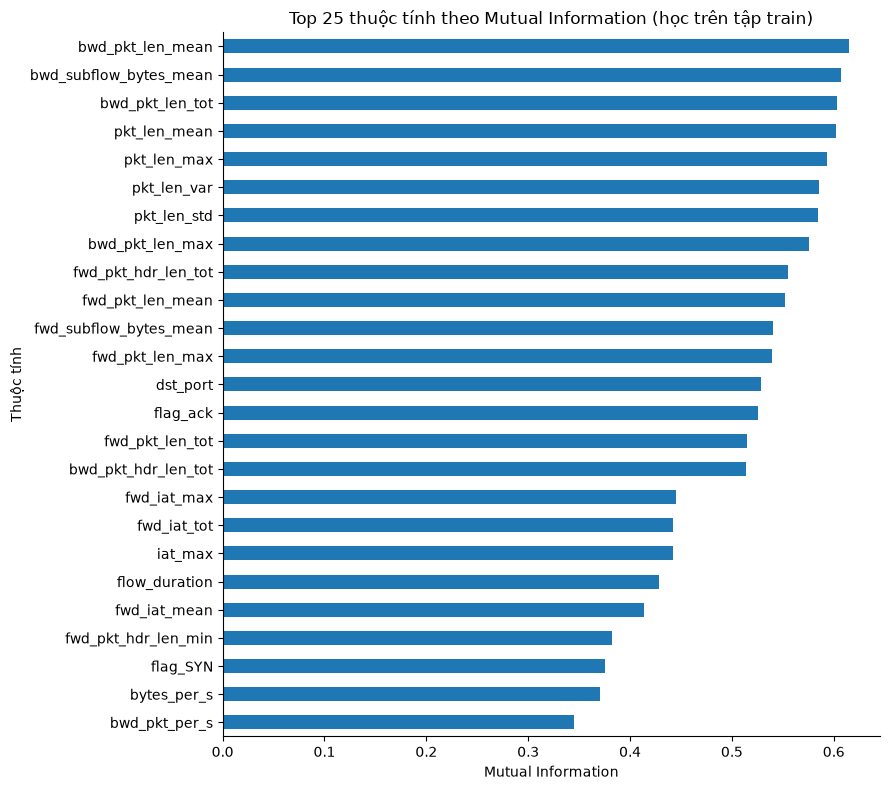

In [69]:
# Phân hạng mức độ quan trọng của thuộc tính
ax = ranking.head(25).sort_values('MI Score').plot.barh(
    x='Thuộc tính',
    y='MI Score',
    figsize=(9, 8),
    legend=False
)

ax.set_xlabel('Mutual Information')
ax.set_ylabel('Thuộc tính')
ax.set_title('Top 25 thuộc tính theo Mutual Information (học trên tập train)')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [70]:
# MI trung bình theo nhóm ý nghĩa - nhóm nào đóng góp nhiều nhất
group_mi = (
    ranking.groupby('Nhóm')
    .agg(**{
        'Số thuộc tính': ('Thuộc tính', 'size'),
        'MI trung bình': ('MI Score', 'mean'),
        'MI cao nhất': ('MI Score', 'max'),
    })
    .round(4)
    .sort_values('MI trung bình', ascending=False)
)

group_mi

,Số thuộc tính,MI trung bình,MI cao nhất
Nhóm,,,
Kích thước gói,15,0.4678,0.6147
Luồng con (subflow),4,0.4419,0.6072
Độ dài header,4,0.4406,0.5551
Định danh & kết nối,3,0.3447,0.5282
Thời lượng & tỷ lệ luồng,4,0.3292,0.4287
Số gói & tốc độ,8,0.3264,0.3708
Khoảng thời gian liên gói (IAT),14,0.3118,0.4453
Cờ TCP,9,0.1923,0.5253
Cửa sổ TCP ban đầu,2,0.1834,0.2444


# 10. Preprocess – Feature Selection

Chia thuộc tính thành ba nhóm, sau đó dùng mô hình trên tập validation (tách ra từ train, **không
dùng tập test**) để xác nhận bộ thuộc tính nào nên chọn.

In [71]:
# Bảng ba nhóm quyết định
drop_model_cols = id_cols + [label_col] + leak_cols + constant_cols + drop_constant + drop_missing

group_decision = pd.DataFrame([
    [
        'Định danh, biến hằng, rò rỉ mục tiêu',
        'Loại khỏi mô hình',
        len(drop_model_cols),
        ', '.join(drop_model_cols)
    ],
    [
        'Thuộc tính có ý nghĩa và giá trị dự báo',
        'Giữ',
        int(ranking['Quyết định'].eq('Giữ').sum()),
        ', '.join(ranking.loc[ranking['Quyết định'].eq('Giữ'), 'Thuộc tính'].head(10)) + ' ...'
    ],
    [
        'Thiếu nhiều, dư thừa, liên quan thấp',
        'Thử nghiệm trước khi quyết định',
        int(ranking['Quyết định'].eq('Thử nghiệm').sum()),
        ', '.join(ranking.loc[ranking['Quyết định'].eq('Thử nghiệm'), 'Thuộc tính'].head(10)) + ' ...'
    ],
], columns=['Nhóm', 'Quyết định', 'Số thuộc tính', 'Ví dụ'])

group_decision

,Nhóm,Quyết định,Số thuộc tính,Ví dụ
0,"Định danh, biến hằng, rò rỉ mục tiêu",Loại khỏi mô hình,9,"flow_id, src_addr, dst_addr, timestamp, label,..."
1,Thuộc tính có ý nghĩa và giá trị dự báo,Giữ,47,"bwd_pkt_len_mean, bwd_subflow_bytes_mean, bwd_..."
2,"Thiếu nhiều, dư thừa, liên quan thấp",Thử nghiệm trước khi quyết định,30,"pkt_len_mean, pkt_len_max, pkt_len_std, bwd_pk..."


In [72]:
# Lý do loại từng cột định danh và cột rò rỉ
drop_reason = pd.DataFrame([
    ['flow_id', f'{nunique_raw["flow_id"] / len(df_raw) * 100:.1f}% giá trị phân biệt',
     'Gần như duy nhất, mô hình chỉ học thuộc từng dòng'],
    ['src_addr', f'{nunique_raw["src_addr"]} địa chỉ',
     'Nếu mô hình nhớ IP thì khó tổng quát khi gặp mạng khác'],
    ['dst_addr', f'{nunique_raw["dst_addr"]} địa chỉ',
     'Cùng lý do với src_addr'],
    ['timestamp', 'Unix microsecond',
     'Dùng trực tiếp sẽ học lịch thu thập thay vì hành vi; chỉ tách ra date và hour cho kho dữ liệu'],
    ['source_day', '5 ngày thu thập',
     'Mỗi ngày là một nhóm kịch bản tấn công nên biết ngày là gần như biết nhãn'],
    [label_col, '14 nhãn',
     'Chính nó sinh ra biến mục tiêu is_attack'],
], columns=['Thuộc tính', 'Bằng chứng', 'Lý do loại'])

drop_reason

,Thuộc tính,Bằng chứng,Lý do loại
0,flow_id,51.3% giá trị phân biệt,"Gần như duy nhất, mô hình chỉ học thuộc từng dòng"
1,src_addr,268 địa chỉ,Nếu mô hình nhớ IP thì khó tổng quát khi gặp m...
2,dst_addr,18095 địa chỉ,Cùng lý do với src_addr
3,timestamp,Unix microsecond,Dùng trực tiếp sẽ học lịch thu thập thay vì hà...
4,source_day,5 ngày thu thập,Mỗi ngày là một nhóm kịch bản tấn công nên biế...
5,label,14 nhãn,Chính nó sinh ra biến mục tiêu is_attack


In [73]:
# Tách validation từ train để so sánh các bộ thuộc tính; tập test cuối không dùng ở bước này
fit_idx, valid_idx = train_test_split(
    train_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df_clean.loc[train_idx, target_col]
)

n_fit_per_class = min(
    SAMPLE_MODEL // 2,
    int(df_clean.loc[fit_idx, target_col].value_counts().min())
)
n_valid_per_class = min(
    SAMPLE_MODEL // 4,
    int(df_clean.loc[valid_idx, target_col].value_counts().min())
)

fit_sample_idx = (
    df_clean.loc[fit_idx].groupby(target_col, observed=True)
    .sample(n=n_fit_per_class, random_state=RANDOM_STATE).index
)
valid_sample_idx = (
    df_clean.loc[valid_idx].groupby(target_col, observed=True)
    .sample(n=n_valid_per_class, random_state=RANDOM_STATE).index
)

print('Số dòng fit:', len(fit_sample_idx), '- validation:', len(valid_sample_idx))

Số dòng fit: 200000 - validation: 100000


In [74]:
def prepare_matrix(cols, fit_rows, other_rows):
    # Điền khuyết và mã hóa bằng thống kê học từ fit_rows, áp dụng y nguyên sang other_rows
    X_fit = df_clean.loc[fit_rows, cols].copy()
    X_other = df_clean.loc[other_rows, cols].copy()

    for col in cols:
        if pd.api.types.is_numeric_dtype(X_fit[col]):
            median = pd.to_numeric(X_fit[col], errors='coerce').median()
            fill = median if pd.notna(median) else 0
            for frame in (X_fit, X_other):
                frame[col] = (
                    pd.to_numeric(frame[col], errors='coerce')
                    .replace([np.inf, -np.inf], np.nan)
                    .fillna(fill)
                    .astype('float64')
                )
        else:
            codes, uniques = pd.factorize(X_fit[col].astype('string').fillna('__MISSING__'))
            mapping = {value: i for i, value in enumerate(uniques)}
            X_fit[col] = codes
            X_other[col] = (
                X_other[col].astype('string').fillna('__MISSING__')
                .map(mapping).fillna(-1).astype('int64')
            )

    return X_fit, X_other


def eval_feature_set(name, cols):
    X_fit, X_valid = prepare_matrix(cols, fit_sample_idx, valid_sample_idx)
    y_fit = df_clean.loc[fit_sample_idx, target_col]
    y_valid = df_clean.loc[valid_sample_idx, target_col]

    model = DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE)
    model.fit(X_fit, y_fit)
    pred = model.predict(X_valid)

    return [
        name,
        len(cols),
        round(accuracy_score(y_valid, pred), 4),
        round(f1_score(y_valid, pred), 4),
    ]

In [75]:
# So sánh hiệu quả phân lớp giữa các bộ thuộc tính trên validation
keep_cols = ranking.loc[ranking['Quyết định'].eq('Giữ'), 'Thuộc tính'].tolist()

feature_sets = {
    'Tất cả thuộc tính hợp lệ': candidate_cols,
    'Chỉ nhóm Giữ': keep_cols,
    'Top 20 theo MI': ranking['Thuộc tính'].head(20).tolist(),
    'Top 10 theo MI': ranking['Thuộc tính'].head(10).tolist(),
}

compare_table = pd.DataFrame(
    [eval_feature_set(name, cols) for name, cols in feature_sets.items()],
    columns=['Bộ thuộc tính', 'Số thuộc tính', 'Accuracy', 'F1-score']
)

compare_table

,Bộ thuộc tính,Số thuộc tính,Accuracy,F1-score
0,Tất cả thuộc tính hợp lệ,77,0.9988,0.9988
1,Chỉ nhóm Giữ,47,0.9978,0.9978
2,Top 20 theo MI,20,0.9971,0.9971
3,Top 10 theo MI,10,0.9957,0.9957


In [76]:
# Chọn bộ có F1 cao nhất; nếu chênh lệch dưới 0,002 thì ưu tiên bộ gọn hơn
best_f1 = compare_table['F1-score'].max()
best_row = (
    compare_table[compare_table['F1-score'] >= best_f1 - 0.002]
    .sort_values('Số thuộc tính')
    .iloc[0]
)

print('Bộ thuộc tính tốt nhất trên validation:', best_row['Bộ thuộc tính'])
print('Accuracy:', best_row['Accuracy'], '- F1-score:', best_row['F1-score'])

Bộ thuộc tính tốt nhất trên validation: Top 20 theo MI
Accuracy: 0.9971 - F1-score: 0.9971


In [77]:
# Thuộc tính bắt buộc giữ để notebook 02 (kho dữ liệu) và 03 (khai phá luật) dùng được
# src_port chỉ phục vụ chiều kho dữ liệu, không kỳ vọng nhiều về mặt dự báo
required_cols = [
    'ip_prot', 'src_port', 'dst_port', 'flow_duration', 'fwd_pkt_cnt', 'bwd_pkt_cnt',
    'fwd_pkt_len_tot', 'bwd_pkt_len_tot', 'pkt_len_mean', 'pkt_len_std',
    'bytes_per_s', 'pkt_per_s', 'iat_mean', 'iat_std', 'flag_SYN', 'flag_ack'
]

chosen = set(feature_sets[best_row['Bộ thuộc tính']]) | set(required_cols)
selected_features = [col for col in ranking['Thuộc tính'] if col in chosen]

print('Số thuộc tính chính thức:', len(selected_features))
print('Thêm vào vì notebook sau cần:', sorted(set(required_cols) - set(feature_sets[best_row['Bộ thuộc tính']])))
selected_features

Số thuộc tính chính thức: 29
Thêm vào vì notebook sau cần: ['bwd_pkt_cnt', 'bytes_per_s', 'flag_SYN', 'fwd_pkt_cnt', 'iat_mean', 'iat_std', 'ip_prot', 'pkt_per_s', 'src_port']


['bwd_pkt_len_mean',
 'bwd_subflow_bytes_mean',
 'bwd_pkt_len_tot',
 'pkt_len_mean',
 'pkt_len_max',
 'pkt_len_var',
 'pkt_len_std',
 'bwd_pkt_len_max',
 'fwd_pkt_hdr_len_tot',
 'fwd_pkt_len_mean',
 'fwd_subflow_bytes_mean',
 'fwd_pkt_len_max',
 'dst_port',
 'flag_ack',
 'fwd_pkt_len_tot',
 'bwd_pkt_hdr_len_tot',
 'fwd_iat_max',
 'fwd_iat_tot',
 'iat_max',
 'flow_duration',
 'flag_SYN',
 'bytes_per_s',
 'pkt_per_s',
 'bwd_pkt_cnt',
 'fwd_pkt_cnt',
 'iat_mean',
 'ip_prot',
 'iat_std',
 'src_port']

In [78]:
# Danh sách giữ / loại cuối cùng
selection_table = pd.concat([
    ranking[['Thuộc tính', 'Nhóm', 'Missing % (train)', 'MI Score', 'Trùng lặp với']]
    .assign(**{
        'Kết luận': np.where(ranking['Thuộc tính'].isin(selected_features), 'Giữ', 'Loại'),
    }),
    pd.DataFrame({
        'Thuộc tính': drop_model_cols,
        'Nhóm': [infer_group(col) for col in drop_model_cols],
        'Missing % (train)': np.nan,
        'MI Score': np.nan,
        'Trùng lặp với': '',
        'Kết luận': 'Loại',
    }),
], ignore_index=True)

selection_table.to_csv(OUT_DIR / 'feature_selection.csv', index=False)

print(selection_table['Kết luận'].value_counts().to_dict())
selection_table

{'Loại': 57, 'Giữ': 29}


,Thuộc tính,Nhóm,Missing % (train),MI Score,Trùng lặp với,Kết luận
0,bwd_pkt_len_mean,Kích thước gói,0.0,0.614666,,Giữ
1,bwd_subflow_bytes_mean,Luồng con (subflow),0.0,0.607241,,Giữ
2,bwd_pkt_len_tot,Kích thước gói,0.0,0.603034,,Giữ
3,pkt_len_mean,Kích thước gói,0.0,0.601992,bwd_pkt_len_mean,Giữ
4,pkt_len_max,Kích thước gói,0.0,0.593053,bwd_pkt_len_mean,Giữ
...,...,...,...,...,...,...
81,label,Nhãn & nguồn dữ liệu,NaN,NaN,,Loại
82,source_day,Nhãn & nguồn dữ liệu,NaN,NaN,,Loại
83,flag_urg,Cờ TCP,NaN,NaN,,Loại
84,fwd_flag_urg,Cờ TCP,NaN,NaN,,Loại


# 11. Preprocess – Data Transformation

Từ **cùng một bộ bản ghi và cùng một bộ thuộc tính**, tạo hai dạng biểu diễn:

| Nhánh | Biến đổi | Dùng cho |
| --- | --- | --- |
| Classification | Điền khuyết median, chuẩn hóa khi mô hình cần | `03_association_classifiation.ipynb` |
| Association Rules | Rời rạc hóa theo phân vị, mã hóa thành item | CHARM và FP-Growth |

Mọi ngưỡng và thống kê đều học từ `train_idx` rồi áp dụng y nguyên cho test.

In [79]:
# Dữ liệu nền sau làm sạch và lựa chọn thuộc tính
keep_meta = [target_col, label_col, 'date', 'hour', 'timestamp']
df_final = df_clean[selected_features + keep_meta].copy()

print('Dữ liệu nền:', df_final.shape)
df_final.head()

Dữ liệu nền: (1837498, 34)


,bwd_pkt_len_mean,bwd_subflow_bytes_mean,bwd_pkt_len_tot,pkt_len_mean,pkt_len_max,pkt_len_var,pkt_len_std,bwd_pkt_len_max,fwd_pkt_hdr_len_tot,fwd_pkt_len_mean,fwd_subflow_bytes_mean,fwd_pkt_len_max,dst_port,flag_ack,fwd_pkt_len_tot,bwd_pkt_hdr_len_tot,fwd_iat_max,fwd_iat_tot,iat_max,flow_duration,flag_SYN,bytes_per_s,pkt_per_s,bwd_pkt_cnt,fwd_pkt_cnt,iat_mean,ip_prot,iat_std,src_port,is_attack,label,date,hour,timestamp
0,201.5,806.000000,6448.0,158.333333,403.0,31450.099291,177.341758,403.0,512.0,72.0,144.000000,72.0,56108,48.0,1152.0,1024.0,16400110.0,112740348.0,16399772.0,112740690.0,0.0,67.411331,0.425756,32.0,16.0,2.398738e+06,6,5.798698e+06,3268,0,benign,2017-07-07,11,1499428790315195
1,316.0,632.000000,5056.0,239.666667,403.0,30619.460993,174.984174,316.0,1024.0,201.5,806.000000,403.0,389,48.0,6448.0,512.0,16399782.0,112740560.0,16399782.0,112740560.0,0.0,102.039585,0.425756,16.0,32.0,2.398735e+06,6,5.798710e+06,42144,0,benign,2017-07-07,11,1499428790316273
2,0.0,0.000000,0.0,8.000000,8.0,0.000000,0.000000,0.0,32.0,8.0,32.000000,8.0,0,0.0,32.0,0.0,53431.0,54760.0,53431.0,54760.0,0.0,584.368152,73.046019,0.0,4.0,1.825333e+04,2,3.046984e+04,0,0,benign,2017-07-07,12,1499428834843793
3,0.0,0.000000,0.0,28.000000,28.0,0.000000,0.000000,0.0,176.0,28.0,616.000000,28.0,5355,0.0,616.0,0.0,100055.0,100126.0,100055.0,100126.0,0.0,6152.248167,219.723149,0.0,22.0,4.767905e+03,17,2.183302e+04,63210,0,benign,2017-07-07,12,1499428834845380
4,59.0,131.111111,1180.0,59.000000,68.0,46.153846,6.793662,62.0,160.0,59.0,131.111111,68.0,137,0.0,1180.0,160.0,50763154.0,93069292.0,50763066.0,93069427.0,0.0,25.357414,0.429787,20.0,20.0,2.386396e+06,17,9.205496e+06,137,0,benign,2017-07-07,12,1499428835164943


## Nhánh Classification

In [80]:
# Điền khuyết bằng thống kê học từ tập train
fill_values = {}

for col in selected_features:
    if pd.api.types.is_numeric_dtype(df_final[col]):
        value = pd.to_numeric(df_final.loc[train_idx, col], errors='coerce').median()
        if pd.isna(value):
            value = 0
        if pd.api.types.is_integer_dtype(df_final[col]):
            value = int(round(value))
        fill_values[col] = value
    else:
        mode = df_final.loc[train_idx, col].mode(dropna=True)
        fill_values[col] = mode.iloc[0] if len(mode) else 'Không rõ'

df_ml = df_final.copy()
for col, value in fill_values.items():
    df_ml[col] = df_ml[col].fillna(value)

print('Số giá trị thiếu còn lại:', int(df_ml[selected_features].isna().sum().sum()))

pd.Series(fill_values).rename('Giá trị điền khuyết (học từ train)').to_frame()

Số giá trị thiếu còn lại: 0


,Giá trị điền khuyết (học từ train)
bwd_pkt_len_mean,122.000000
bwd_subflow_bytes_mean,206.000000
bwd_pkt_len_tot,234.000000
pkt_len_mean,84.500000
pkt_len_max,138.000000
pkt_len_var,3267.000000
pkt_len_std,57.157677
bwd_pkt_len_max,134.000000
fwd_pkt_hdr_len_tot,32.000000
fwd_pkt_len_mean,43.000000


In [81]:
# Mã hóa biến phân loại nếu còn
encode_cols = [col for col in selected_features if not pd.api.types.is_numeric_dtype(df_ml[col])]

if encode_cols:
    for col in encode_cols:
        categories = sorted(df_ml.loc[train_idx, col].astype('string').dropna().unique().tolist())
        mapping = {value: i for i, value in enumerate(categories)}
        df_ml[col + '_code'] = df_ml[col].astype('string').map(mapping).fillna(-1).astype('int16')
    print('Các cột mã hóa đã thêm:', [col + '_code' for col in encode_cols])
else:
    print('Không còn biến phân loại dạng chuỗi; ip_prot, src_port, dst_port đã là mã số nguyên')

Không còn biến phân loại dạng chuỗi; ip_prot, src_port, dst_port đã là mã số nguyên


In [82]:
# Chuẩn hóa chỉ cần cho mô hình tuyến tính; cây quyết định và rừng ngẫu nhiên không cần
# Scaler học trên train rồi áp sang test, không fit trên toàn bộ dữ liệu
scale_cols = [
    col for col in selected_features
    if pd.api.types.is_numeric_dtype(df_ml[col]) and col not in code_cols
]

scaler = StandardScaler().fit(df_ml.loc[train_idx, scale_cols].astype('float64'))

print('Số thuộc tính được chuẩn hóa:', len(scale_cols))
pd.DataFrame({
    'Thuộc tính': scale_cols,
    'Mean (train)': scaler.mean_.round(3),
    'Std (train)': scaler.scale_.round(3),
}).head(15)

Số thuộc tính được chuẩn hóa: 26


,Thuộc tính,Mean (train),Std (train)
0,bwd_pkt_len_mean,475.965,737.861
1,bwd_subflow_bytes_mean,12509.811,1941957.639
2,bwd_pkt_len_tot,23095.137,2733204.640
3,pkt_len_mean,305.228,462.280
4,pkt_len_max,1388.866,2375.966
5,pkt_len_var,948431.221,2626875.560
6,pkt_len_std,477.595,848.725
7,bwd_pkt_len_max,1351.788,2364.590
8,fwd_pkt_hdr_len_tot,270.709,18790.868
9,fwd_pkt_len_mean,60.693,98.796


In [83]:
# Đánh dấu train/test để các notebook sau dùng đúng một cách chia
df_ml['split'] = np.where(df_ml.index.isin(set(train_idx)), 'train', 'test')

print(df_ml['split'].value_counts().to_dict())

{'train': 1469998, 'test': 367500}


## Nhánh Association Rules

Rời rạc hóa biến liên tục thành `Low / Medium / High` theo phân vị 33% và 66% **học trên train**.
`ip_prot` giữ nguyên mã giao thức; `dst_port` gom theo dịch vụ; `flag_SYN` gom thành 0 / 1 / 2+.
Mỗi luồng trở thành một giao dịch gồm các item dạng `tên=giá trị`, sẵn sàng cho CHARM và FP-Growth.

In [84]:
# Ngưỡng phân vị học trên train
arm_num = [
    'flow_duration', 'pkt_len_mean', 'bwd_pkt_len_mean',
    'bytes_per_s', 'iat_mean', 'fwd_pkt_cnt', 'bwd_pkt_cnt'
]
bin_labels = ['Low', 'Medium', 'High']

bounds = {}
for col in arm_num:
    values = pd.to_numeric(df_ml.loc[train_idx, col], errors='coerce')
    bounds[col] = np.unique(values.dropna().quantile([1 / 3, 2 / 3]).to_numpy())

bound_table = pd.DataFrame({
    'Thuộc tính': arm_num,
    'Ngưỡng 33%': [bounds[col][0] for col in arm_num],
    'Ngưỡng 66%': [bounds[col][-1] for col in arm_num],
    'Số nhóm': [len(bounds[col]) + 1 for col in arm_num],
}).round(3)

bound_table

,Thuộc tính,Ngưỡng 33%,Ngưỡng 66%,Số nhóm
0,flow_duration,27795.000,264548.000,3
1,pkt_len_mean,64.000,146.692,3
2,bwd_pkt_len_mean,83.000,215.000,3
3,bytes_per_s,1305.409,17825.664,3
4,iat_mean,7891.667,61179.000,3
5,fwd_pkt_cnt,2.000,3.000,3
6,bwd_pkt_cnt,2.000,5.000,3


In [85]:
def to_items(frame):
    # Biến đổi bằng đúng ngưỡng đã học trên train
    out = pd.DataFrame(index=frame.index)

    for col in arm_num:
        values = pd.to_numeric(frame[col], errors='coerce').to_numpy(dtype='float64')
        group = np.searchsorted(bounds[col], values, side='right')
        names = np.array(bin_labels[:len(bounds[col]) + 1])
        out[col] = np.where(
            np.isnan(values),
            f'{col}=Unknown',
            np.char.add(f'{col}=', names[np.clip(group, 0, len(names) - 1)])
        )

    out['ip_prot'] = 'ip_prot=' + frame['ip_prot'].astype('string').fillna('Unknown')

    port = pd.to_numeric(frame['dst_port'], errors='coerce')
    out['dst_port'] = np.select(
        [port.isin([80, 8080]), port.eq(443), port.isin([21, 22, 23]), port.lt(1024)],
        ['dst_port=HTTP', 'dst_port=HTTPS', 'dst_port=RemoteAdmin', 'dst_port=WellKnown'],
        default='dst_port=Ephemeral'
    )

    syn = pd.to_numeric(frame['flag_SYN'], errors='coerce')
    out['flag_SYN'] = np.select(
        [syn.eq(0), syn.eq(1)],
        ['flag_SYN=0', 'flag_SYN=1'],
        default='flag_SYN=2+'
    )

    return out

In [86]:
# Giao dịch cho train và test
arm_train = to_items(df_ml.loc[train_idx])
arm_train[target_col] = 'is_attack=' + df_ml.loc[train_idx, target_col].astype('string')

arm_test = to_items(df_ml.loc[test_idx])
arm_test[target_col] = 'is_attack=' + df_ml.loc[test_idx, target_col].astype('string')

n_items = int(sum(arm_train[col].nunique() for col in arm_train.columns))

print('Số giao dịch train:', len(arm_train), '- test:', len(arm_test))
print('Số mục (item) phân biệt:', n_items)
arm_train.head()

Số giao dịch train: 1469998 - test: 367500
Số mục (item) phân biệt: 36


,flow_duration,pkt_len_mean,bwd_pkt_len_mean,bytes_per_s,iat_mean,fwd_pkt_cnt,bwd_pkt_cnt,ip_prot,dst_port,flag_SYN,is_attack
477472,flow_duration=Low,pkt_len_mean=Low,bwd_pkt_len_mean=Low,bytes_per_s=High,iat_mean=Low,fwd_pkt_cnt=Medium,bwd_pkt_cnt=Medium,ip_prot=17,dst_port=WellKnown,flag_SYN=0,is_attack=0
1773055,flow_duration=Low,pkt_len_mean=Low,bwd_pkt_len_mean=Low,bytes_per_s=High,iat_mean=Low,fwd_pkt_cnt=Medium,bwd_pkt_cnt=Medium,ip_prot=17,dst_port=WellKnown,flag_SYN=0,is_attack=0
269468,flow_duration=Low,pkt_len_mean=Low,bwd_pkt_len_mean=Low,bytes_per_s=Low,iat_mean=Low,fwd_pkt_cnt=Low,bwd_pkt_cnt=Low,ip_prot=6,dst_port=Ephemeral,flag_SYN=1,is_attack=1
268764,flow_duration=Low,pkt_len_mean=Low,bwd_pkt_len_mean=Low,bytes_per_s=Low,iat_mean=Low,fwd_pkt_cnt=Low,bwd_pkt_cnt=Low,ip_prot=6,dst_port=Ephemeral,flag_SYN=1,is_attack=1
837689,flow_duration=Medium,pkt_len_mean=Medium,bwd_pkt_len_mean=Medium,bytes_per_s=Medium,iat_mean=Medium,fwd_pkt_cnt=Medium,bwd_pkt_cnt=Medium,ip_prot=17,dst_port=WellKnown,flag_SYN=0,is_attack=0


In [87]:
# Tần suất các mục phổ biến nhất trên train - mức hỗ trợ của từng item
item_support = (
    pd.concat([arm_train[col] for col in arm_train.columns])
    .value_counts()
    .rename_axis('Item')
    .reset_index(name='count')
)
item_support['support (%)'] = (item_support['count'] / len(arm_train) * 100).round(3)

item_support.head(20)

,Item,count,support (%)
0,is_attack=0,1116540,75.955
1,ip_prot=6,759794,51.687
2,flag_SYN=0,750063,51.025
3,dst_port=WellKnown,732816,49.851
4,ip_prot=17,709777,48.284
5,fwd_pkt_cnt=High,677061,46.059
6,bwd_pkt_cnt=Medium,590904,40.198
7,flag_SYN=2+,589036,40.071
8,pkt_len_mean=Medium,495706,33.722
9,bwd_pkt_cnt=High,493584,33.577


In [88]:
# Lưu kết quả cho các notebook sau
df_ml.to_parquet(OUT_DIR / 'flows_clean.parquet', index=False)

arm_train.to_parquet(OUT_DIR / 'arm_items_train.parquet', index=False)
arm_test.to_parquet(OUT_DIR / 'arm_items_test.parquet', index=False)

pd.Series(selected_features, name='Thuộc tính').to_csv(OUT_DIR / 'selected_features.csv', index=False)
clean_table.to_csv(OUT_DIR / 'clean_log.csv', index=False)
item_support.to_csv(OUT_DIR / 'arm_item_support.csv', index=False)

for path in sorted(OUT_DIR.iterdir()):
    print(f'{path.name:32s} {path.stat().st_size / 1024 ** 2:8.2f} MB')

arm_item_support.csv                 0.00 MB
arm_items_test.parquet               1.02 MB
arm_items_train.parquet              4.07 MB
clean_log.csv                        0.00 MB
data_dictionary.csv                  0.01 MB
eda_findings.csv                     0.00 MB
feature_ranking.csv                  0.01 MB
feature_selection.csv                0.01 MB
flows_clean.parquet                135.40 MB
selected_features.csv                0.00 MB


# 12. Preprocess – Before vs After

Bảng tổng kết quan trọng nhất của phần tiền xử lý.

In [89]:
# Thống kê trước và sau tiền xử lý
stats_before = {
    'Số dòng dữ liệu': len(df_raw),
    'Số thuộc tính đầu vào': len(columns_raw) - 1,
    'Số giá trị thiếu': n_null_raw,
    'Số dòng trùng toàn bộ cột': n_dup_all,
    'Số giá trị bất hợp lệ': n_invalid_raw,
}

stats_after = {
    'Số dòng dữ liệu': len(df_ml),
    'Số thuộc tính đầu vào': len(selected_features),
    'Số giá trị thiếu': int(df_ml[selected_features].isna().sum().sum()),
    'Số dòng trùng toàn bộ cột': int(df_ml.duplicated().sum()),
    'Số giá trị bất hợp lệ': 0,
}

comparison = pd.DataFrame({'Trước xử lý': stats_before, 'Sau xử lý': stats_after})
comparison['Chênh lệch'] = comparison['Sau xử lý'] - comparison['Trước xử lý']

print('Số thuộc tính bị loại:', len(columns_raw) - 1 - len(selected_features))
comparison

Số thuộc tính bị loại: 54


,Trước xử lý,Sau xử lý,Chênh lệch
Số dòng dữ liệu,1837498,1837498,0
Số thuộc tính đầu vào,83,29,-54
Số giá trị thiếu,0,0,0
Số dòng trùng toàn bộ cột,0,2,2
Số giá trị bất hợp lệ,1788033,0,-1788033


In [90]:
# Nhật ký tiền xử lý - giải thích nguyên nhân dữ liệu thay đổi
selection_log = pd.DataFrame([
    [
        'Lựa chọn thuộc tính', 0,
        len(columns_raw) - 1 - len(selected_features) - len(constant_cols),
        0,
        'Loại định danh, rò rỉ nhãn, dư thừa và liên quan yếu; dựa trên phân hạng và thử nghiệm mô hình'
    ],
], columns=clean_table.columns)

full_log = pd.concat([clean_table, selection_log], ignore_index=True)
full_log.to_csv(OUT_DIR / 'preprocess_log.csv', index=False)

full_log

,Công đoạn,Số dòng bị loại,Số cột bị loại,Số giá trị xử lý,Lý do
0,Loại trùng toàn bộ cột,0,0,0,Bản ghi lặp hoàn toàn không mang thêm thông tin
1,Loại dòng thiếu nhãn,0,0,0,Không có biến mục tiêu nên không thể dùng cho ...
2,Chuẩn hóa văn bản,0,0,0,"Xóa khoảng trắng đầu/cuối, chuỗi rỗng đổi thàn..."
3,Chuẩn hóa kiểu số,0,0,0,Giá trị không chuyển được thành số đổi sang thiếu
4,Đánh dấu giá trị bất hợp lý,0,0,2270,Giá trị ngoài miền hợp lệ đổi thành thiếu; dòn...
5,Tách mã -1 của cửa sổ TCP,0,0,1785763,"Thêm cờ chỉ báo ['fwd_tcp_init_win_absent', 'b..."
6,Loại thuộc tính hằng,0,3,0,Chỉ có 1 giá trị nên không có khả năng phân bi...
7,Lựa chọn thuộc tính,0,51,0,"Loại định danh, rò rỉ nhãn, dư thừa và liên qu..."


In [91]:
# Số dòng trùng trên bộ thuộc tính đã chọn
# Sau khi giảm còn ít thuộc tính, nhiều luồng khác nhau có cùng giá trị đặc trưng.
# Đây không phải bản ghi lặp không hợp lệ nên giữ nguyên, chỉ ghi nhận để giải thích con số.
n_dup_selected = int(df_ml.duplicated(subset=selected_features + [target_col]).sum())

print('Số dòng trùng trên', len(selected_features), 'thuộc tính đã chọn:', f'{n_dup_selected:,}')
print('Tỷ lệ (%):', round(n_dup_selected / len(df_ml) * 100, 3))
print('Số dòng trùng toàn bộ cột của df_ml:', int(df_ml.duplicated().sum()))

Số dòng trùng trên 29 thuộc tính đã chọn: 11,281
Tỷ lệ (%): 0.614


Số dòng trùng toàn bộ cột của df_ml: 2


In [92]:
# So sánh phân bố lớp trước và sau để chắc chắn tiền xử lý không làm lệch nhãn
label_compare = pd.DataFrame({
    'Trước xử lý (%)': (df_raw[target_col].value_counts(normalize=True) * 100).round(3),
    'Sau xử lý (%)': (df_ml[target_col].value_counts(normalize=True) * 100).round(3),
})
label_compare.index = label_compare.index.map({0: 'safe', 1: 'attack'})

label_compare

,Trước xử lý (%),Sau xử lý (%)
is_attack,,
safe,75.955,75.955
attack,24.045,24.045


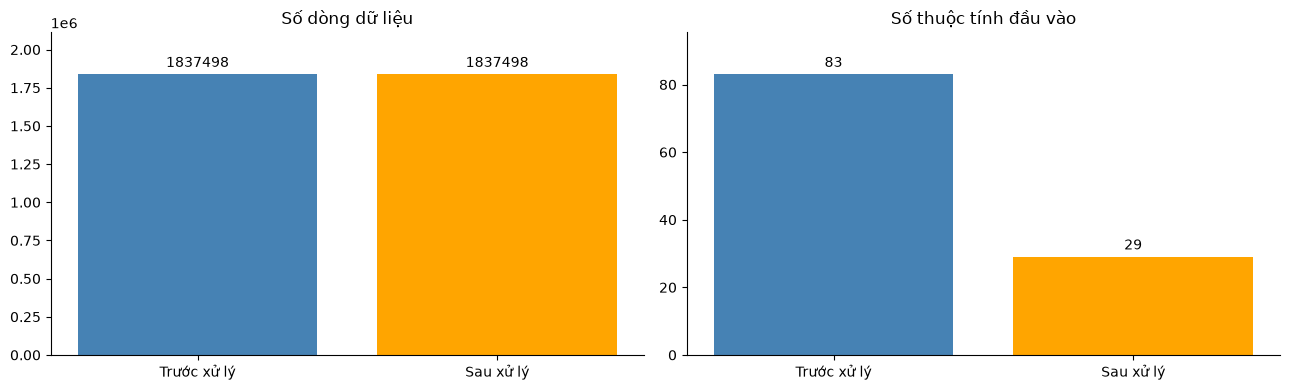

In [93]:
# Biểu đồ đối chiếu trước - sau
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

compare_plot = comparison.loc[['Số dòng dữ liệu', 'Số thuộc tính đầu vào']]

for ax, row in zip(axes, compare_plot.index):
    values = compare_plot.loc[row, ['Trước xử lý', 'Sau xử lý']]
    ax.bar(values.index, values.to_numpy(), color=['steelblue', 'orange'])
    ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)
    ax.set_title(row)
    ax.margins(y=0.15)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

## Đưa gì vào báo cáo

**4 bảng chính**

| Bảng | Biến trong notebook |
| --- | --- |
| Thống kê tổng quan dữ liệu | `overview`, `data_dict` |
| Chất lượng dữ liệu và vấn đề phát hiện | `invalid_table`, `findings_table` |
| Phân hạng và lựa chọn thuộc tính | `ranking`, `compare_table`, `selection_table` |
| Đối chiếu trước – sau | `comparison`, `full_log` |

**6 biểu đồ chính**

1. Tỷ lệ giá trị bất hợp lệ theo thuộc tính (mục 03)
2. Phân bố nhãn 14 lớp theo thang log (mục 04)
3. Histogram thường và log của thuộc tính tiêu biểu (mục 05)
4. Boxplot theo lớp safe / attack (mục 06)
5. Heatmap tương quan 20 thuộc tính (mục 06)
6. Top 25 thuộc tính theo Mutual Information (mục 09)

**Điểm cần nhấn trong báo cáo**

- LYCOS-IDS2017 **không thiếu dữ liệu**, nên phần tiền xử lý không nằm ở điền khuyết mà ở ba việc:
  xử lý mã sai miền (`-1` của cửa sổ TCP, `iat_min` âm), loại thuộc tính không có khả năng phân biệt,
  và chống rò rỉ thông tin (`flow_id`, IP, `timestamp`, `source_day`).
- Outlier **không bị xóa**: với dữ liệu mạng, giá trị cực đoan chính là dấu hiệu của tấn công.
- Mọi ngưỡng (median, phân vị rời rạc hóa, scaler, phân hạng MI) đều học từ `train_idx`,
  nên tập test vẫn độc lập khi đánh giá ở notebook 03.